<img src="Bilder/ost_logo.png" width="240" align="right"/>
<div style="text-align: left"> <b> Machine Learning Projekt</b> <br> HS 2025 <br> <a href="mailto:ryan.mikus@ost.ch"> Ryan Mikus </a> und <a href="mailto:ilija.amato@ost.ch"> Ilija Amato </a> </div>

# 3. Explorative Datenanalyse

In diesem Abschnitt wird die Datenbasis für das Pairs-Trading-Projekt systematisch untersucht. Ziel der explorativen Datenanalyse (EDA) ist es, ein Verständnis für die Struktur, Qualität und statistischen Eigenschaften der Kursdaten zu gewinnen, bevor darauf aufbauend Modelle für das maschinelle Lernen entwickelt werden.

Die analysierten Daten bestehen aus hochfrequenten Kurszeitreihen des S&P 500 mit einer zeitlichen Auflösung von einer Minute (Dateien: `sp500_1min_YYYY-MM-DD.csv`). Jede Zeile repräsentiert den Kurs eines bestimmten Wertpapiers zu einem gegebenen Zeitpunkt.

Das Vorgehen in diesem Kapitel gliedert sich in mehrere Schritte:

1. **Datenüberblick und Datenqualität**  
   Laden des Datensatzes, erste Kennzahlen (Anzahl Zeilen, Anzahl Ticker) und Prüfung auf fehlende Werte.
   Datensatz inspizieren, Datenlücken analyysieren und Datensatz säubern

3. **Untersuchung von Beziehungen zwischen Aktien**  
   Berechnung von Korrelationen zwischen Kursreihen und Darstellung stark korrelierter Aktienbeziehungen in Form eines Netzwerks.

2. **Fazit**
   
Die verwendeten Daten bestehen aus hochfrequenten 1-Minuten-Preisen der im S&P 500 enthaltenen Aktien. Der rohe Datensatz umfasst Kurse vom **07. November 2025** bis zum **DATUM NOCH NICHT DEFINIERT** und enthält insgesamt mehrere millionen Zeilen.

In [11]:
from pairs_trading import data_io as io
from pairs_trading import eda, features
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [12]:
df_clean = io.load_preprocessed_data(
    data_dir="Daten",
    basename="market_data_cleaned"
)


[Preprocessed Data Load]
Pfad: Daten\market_data_cleaned.parquet

[Preprocessed Data]
Shape: (6741003, 7)
Spalten: ['datetime', 'symbol', 'open', 'high', 'low', 'volume', 'close_filled']

Head:
                   datetime symbol        open        high         low  \
0 2025-11-07 14:30:00+00:00      A  146.520004  147.119995  145.729996   
1 2025-11-07 14:31:00+00:00      A         NaN         NaN         NaN   
2 2025-11-07 14:32:00+00:00      A  146.089996  146.089996  146.089996   
3 2025-11-07 14:33:00+00:00      A         NaN         NaN         NaN   
4 2025-11-07 14:34:00+00:00      A  146.049698  146.049698  146.049698   

    volume  close_filled  
0  13361.0    145.729996  
1      NaN    145.909996  
2    427.0    146.089996  
3      NaN    146.069847  
4   1387.0    146.049698  


## 3.3. Deskriptive Analyse der Zeitreihen

In diesem Abschnitt wird die deskriptive explorative Datenanalyse der intraday Preiszeitreihen beschrieben, die als vorbereitender Schritt vor der Modellierung durchgeführt wurde. Ziel dieser Analyse ist es, die statistischen Eigenschaften der Renditen zu charakterisieren, Unterschiede zwischen den einzelnen Wertpapieren (Cross-Section) sichtbar zu machen sowie systematische intraday Muster zu identifizieren.

Die Ausgangsdaten liegen im sogenannten *Long-Format* vor und bestehen aus Zeitstempeln, Symbolen und Preisen. Um eine einheitliche zeitliche Ausrichtung sowie einen Vergleich zwischen verschiedenen Symbolen zu ermöglichen, werden die Daten in ein *Wide-Format* überführt. In dieser Darstellung entspricht jede Spalte einem Symbol, während die Zeilen durch gemeinsame Zeitstempel indiziert sind. Das kann nur gemacht werden, wenn die Daten gesäubert wurden.

Zusätzlich werden die Preise auf eine feste intraday Frequenz (z. B. 5-Minuten-Intervalle) resampled. Dabei wird jeweils der letzte beobachtete Preis innerhalb eines Zeitintervalls verwendet. Diese Vorgehensweise stellt sicher, dass alle Zeitreihen auf einem gemeinsamen Zeitraster liegen und reduziert Verzerrungen durch unregelmäßige Handelsaktivität.

Die Analyse basiert nicht auf Preisen, sondern auf Renditen. Konkret werden logarithmische Renditen berechnet als

$$
r_t = \log(p_t) - \log(p_{t-1}),
$$

wobei $p_t$ den Preis zum Zeitpunkt $t$ bezeichnet. Log-Renditen werden verwendet, da sie über die Zeit additiv sind und skaleninvariant, wodurch ein Vergleich zwischen Assets mit unterschiedlichen Preisniveaus möglich wird.

Für jedes Symbol werden deskriptive Statistiken auf Basis der Renditeverteilung berechnet. Diese Kennzahlen beschreiben sowohl die zentrale Lage als auch die Streuung und das Tail-Verhalten der Renditen.

Berechnet werden unter anderem:

- **Anzahl Beobachtungen (`n_obs`)**: Maß für Datenverfügbarkeit und Handelsaktivität.
- **Mittelwert (`mean`)**: Durchschnittliche Rendite.
- **Standardabweichung (`std`)**: Maß für Volatilität.
- **Quantile (`q01`, `q05`, `median`, `q95`, `q99`)**: Empirische Quantile der Renditeverteilung zur Beschreibung von Extrembewegungen.
- **Schiefe (`skew`)**: Maß für die Asymmetrie der Verteilung.
- **Kurtosis (`kurtosis`)**: Maß für die Ausprägung der Tails im Vergleich zur Normalverteilung (Normalverteilung ≈ 3).
- **Anteil Nullrenditen (`pct_zero_returns`)**: Proxy für Illiquidität oder Preisstarrheit.
- **Mittlere absolute Rendite (`mean_abs_return`)**: Alternatives Volatilitätsmaß.
- **99-%-Quantil der absoluten Renditen (`abs_q99`)**: Charakterisiert extreme Renditebewegungen.

Die Quantile werden empirisch aus den beobachteten Renditen geschätzt und erlauben eine explizite Analyse von Tail-Risiken, die durch Varianzmaße allein nicht vollständig erfasst werden.

Um die Verteilung der berechneten Statistiken über alle Symbole hinweg darzustellen, werden verschiedene cross-sectionale Diagramme erzeugt.

Histogramme zeigen die Verteilung einzelner statistischer Kennzahlen (z. B. Volatilität oder Anteil von Nullrenditen) über alle Symbole hinweg. Jedes Histogramm repräsentiert somit eine Kennzahl, aggregiert über die gesamte Asset-Population.

Diese Darstellungen ermöglichen eine visuelle Identifikation von Schiefe, Heavy-Tail-Verhalten sowie Ausreißern in der Cross-Section.

Boxplots fassen mehrere statistische Kennzahlen gleichzeitig zusammen und visualisieren Median, Interquartilsabstand und Streuung der Cross-Section. Ausreißer werden unterdrückt, um den Fokus auf das typische Verhalten der Mehrzahl der Assets zu legen.

Zur Untersuchung zeitabhängiger intraday Effekte wird ein Intraday-Volatilitätsprofil berechnet. Für jede Tageszeit wird die durchschnittliche absolute Rendite über alle Symbole hinweg bestimmt:

$$
\text{IntradayVol}(t) = \frac{1}{N} \sum_{i=1}^{N} |r_{i,t}|.
$$

Dieses Profil beschreibt systematische Schwankungen der Marktaktivität und Volatilität im Tagesverlauf, unabhängig von einzelnen Assets.

Das resultierende Diagramm zeigt die durchschnittliche intraday Volatilität als Funktion der Tageszeit.

Da eine visuelle Inspektion aller Zeitreihen nicht praktikabel ist, wird eine Teilmenge repräsentativer Symbole für eine detaillierte Betrachtung ausgewählt. Die Auswahl erfolgt anhand der Volatilität und umfasst:

- Symbole mit hoher Volatilität `n_top_vol`
- Symbole mit mittlerer Volatilität `n_bottom_vol`
- Symbole mit niedriger Volatilität`n_median_vol`

Diese sind einstellbar und standardmässig 5. Diese Auswahl stellt sicher, dass unterschiedliche Verhaltensregime innerhalb der Asset-Population abgedeckt sind und ermöglicht eine qualitative Überprüfung der zuvor berechneten statistischen Kennzahlen.

Die deskriptive EDA liefert folgende Ergebnisse:
- Ein Preis-Panel im Wide-Format
- Ein Rendite-Panel im Wide-Format
- Eine Tabelle mit deskriptiven Statistiken pro Symbol
- Eine Auswahl repräsentativer Symbole für Detailanalysen
- Ein Intraday-Volatilitätsprofil

Diese Ergebnisse bilden die Grundlage für die anschließende Interpretation sowie für die Ableitung von Modellierungs- und Feature-Engineering-Entscheidungen.

An dieser Stelle werden die Daten ebenfalls transformiert in das *Wide-Format*. Hier kann auch die Frequenz eingestellt werden für die gesäuberten Daten

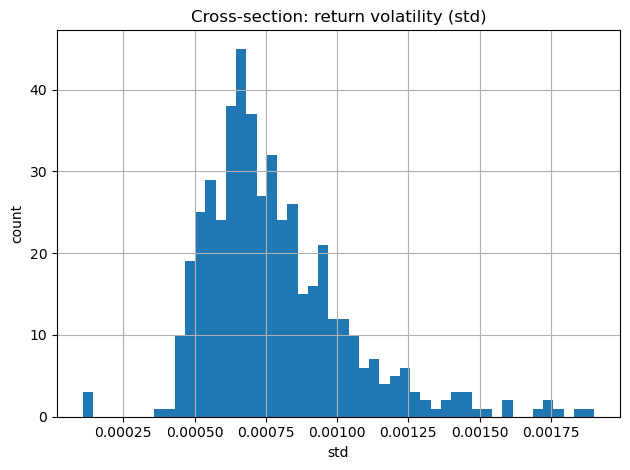

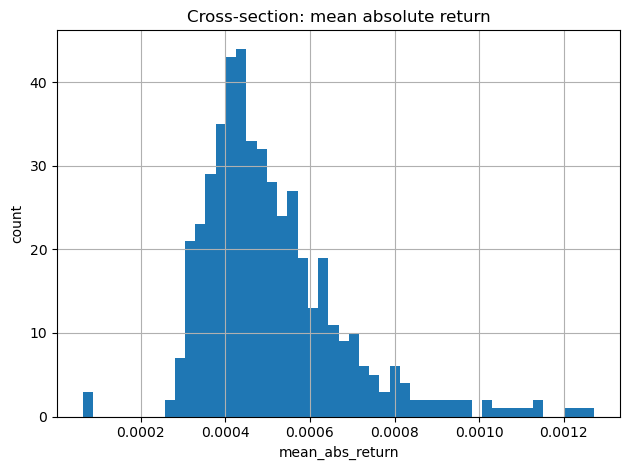

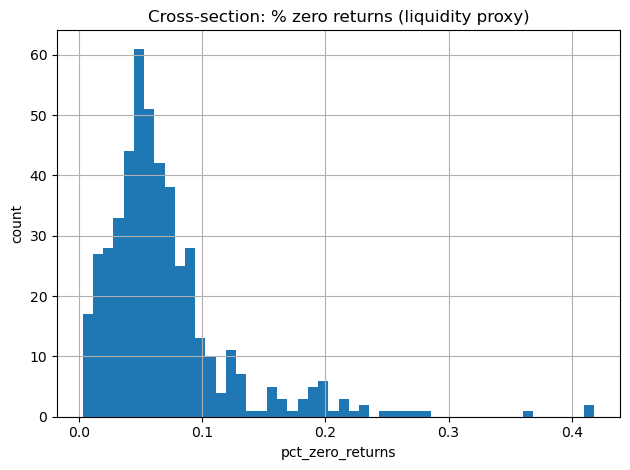

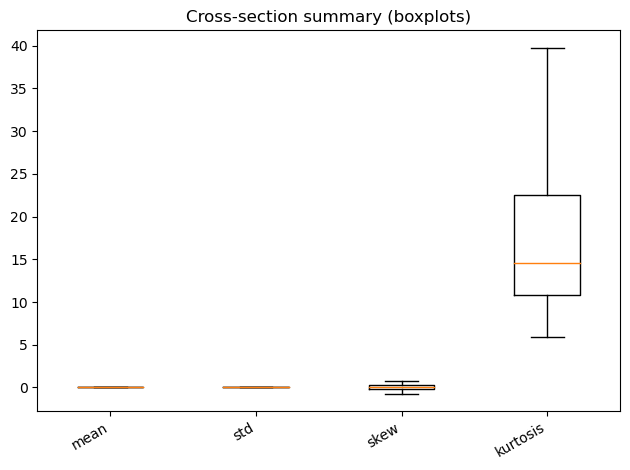

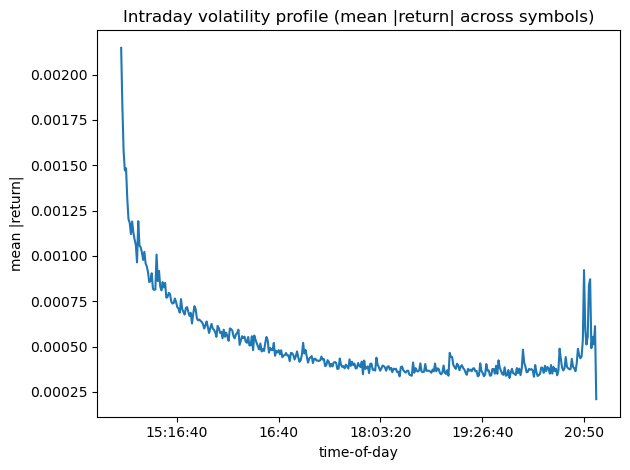

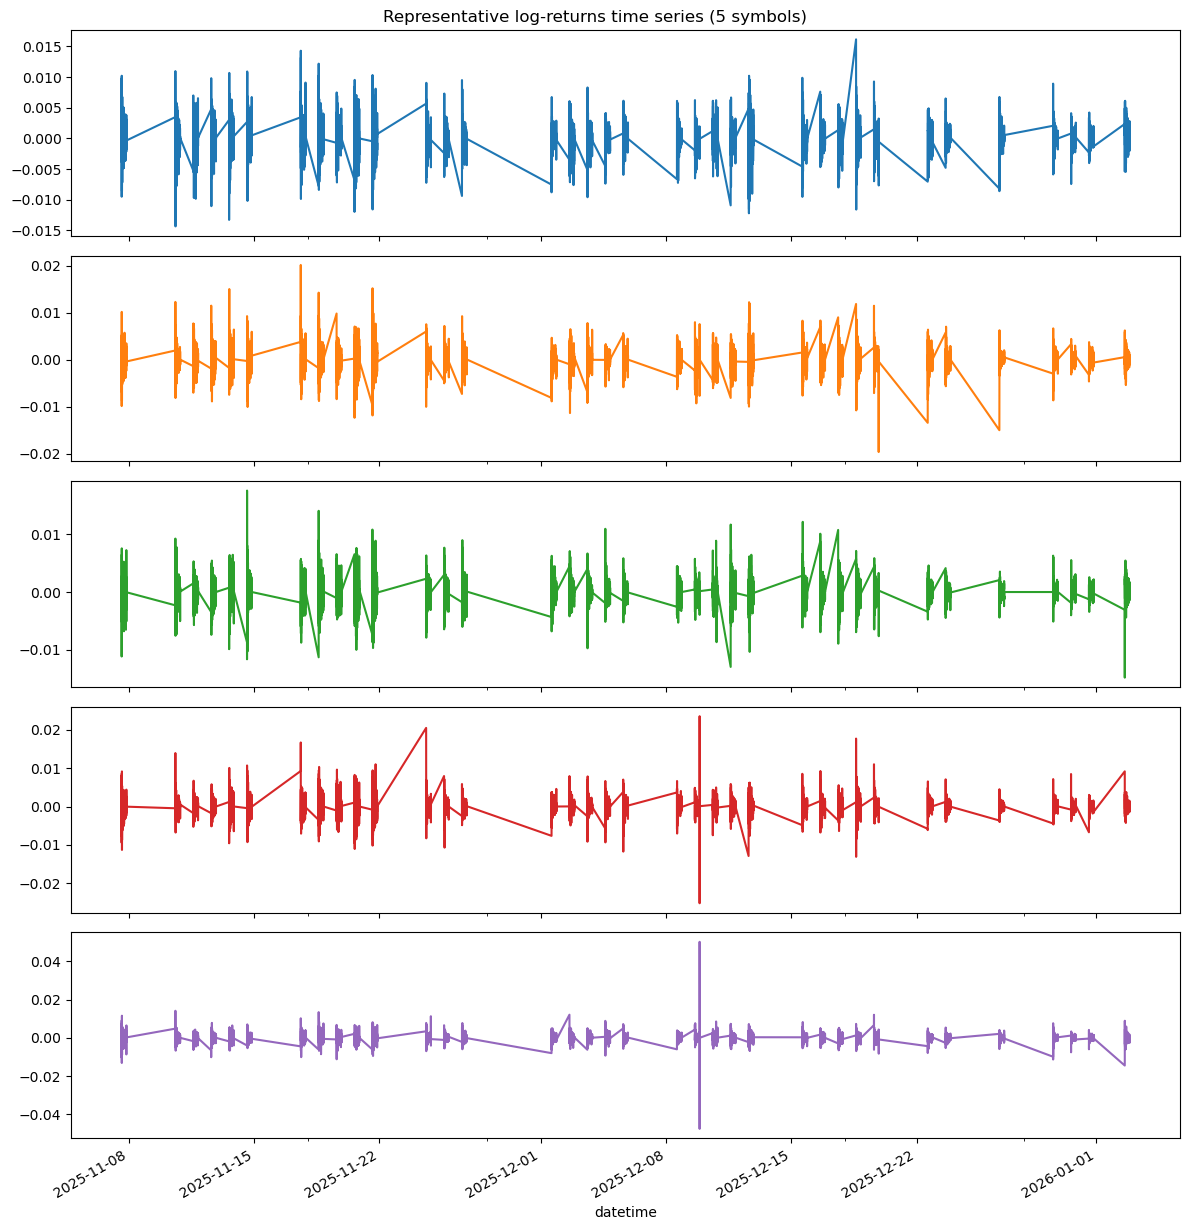

,n_obs,mean,std,q01,q05,median,q95,q99,skew,kurtosis,pct_zero_returns,mean_abs_return,abs_q99
symbol,,,,,,,,,,,,,
WDC,14038,-7.256531e-06,0.001902,-0.005802,-0.002958,0.000000e+00,0.002846,0.005534,-0.111963,9.063782,0.013179,0.001272,0.007012
STX,14038,-8.819109e-06,0.001852,-0.005509,-0.002905,0.000000e+00,0.002777,0.005273,-0.072045,10.892338,0.014247,0.001220,0.006721
HOOD,14038,-1.018335e-05,0.001773,-0.005101,-0.002813,0.000000e+00,0.002663,0.005036,0.020147,8.664971,0.011469,0.001226,0.006069
MU,14038,-4.840458e-06,0.001745,-0.004877,-0.002672,0.000000e+00,0.002547,0.004930,0.189374,16.355622,0.005699,0.001149,0.006192
APP,14038,-8.356105e-06,0.001732,-0.004660,-0.002516,0.000000e+00,0.002475,0.004664,0.270282,98.840037,0.006126,0.001118,0.005748
Q,14037,-1.553115e-06,0.001707,-0.004825,-0.002618,0.000000e+00,0.002614,0.004971,0.009270,12.442424,0.076583,0.001094,0.006067
COIN,14038,-1.179954e-05,0.001614,-0.004517,-0.002541,0.000000e+00,0.002443,0.004378,0.091570,7.925003,0.007907,0.001131,0.005645
ALB,14038,1.884895e-05,0.001604,-0.004472,-0.002355,0.000000e+00,0.002446,0.004864,0.462043,11.245749,0.023151,0.001072,0.005573
FSLR,14038,2.692125e-06,0.001515,-0.004127,-0.002366,0.000000e+00,0.002363,0.004339,-0.013355,12.430193,0.023508,0.001026,0.005170


Representative symbols for drill-down: ['WDC', 'STX', 'HOOD', 'MU', 'APP', 'IFF', 'HSIC', 'BA', 'LDOS', 'TAP', 'KO', 'O', 'EA', 'HOLX', 'DAY']


In [13]:
out = eda.run_descriptive_eda(
    df_clean,
    timestamp_col="datetime",
    symbol_col="symbol",
    price_col="close_filled",
    freq="1min", # Frequenz der gesäuberten Daten
    plot=True,
    max_representative_plots=5,
)

stats = out["stats"]
representative = out["representative_symbols"]

display(stats.head(20))
print("Representative symbols for drill-down:", representative)

INTERPRETATION DER DIAGRAMME UND WAS DAS FÜR DAS MODELL HEISST.

## 3.4. Explorative Analyse von Aktien-Beziehungen

### 3.4.1. Korrelation

Zur Untersuchung preisbasierter Abhängigkeiten wird zunächst die Korrelationsmatrix der logarithmierten Preise berechnet. Die Logarithmierung reduziert langfristige Trends und Skalenunterschiede zwischen Aktien und erlaubt eine stabilere Interpretation linearer Zusammenhänge über den betrachteten Zeitraum.

Anschließend werden exemplarisch Paare mit sehr hoher Korrelation (r > 0.97) identifiziert. Diese Filterung dient ausschließlich der explorativen Analyse und stellt keine Paarsuche oder Auswahlregel dar.

Für die Visualisierung wird eine Heatmap für eine repräsentative Teilmenge von Aktien erstellt. Die Auswahl erfolgt auf Basis der durchschnittlichen Korrelationen, um eine übersichtliche Darstellung stark miteinander korrelierender Zeitreihen zu ermöglichen.

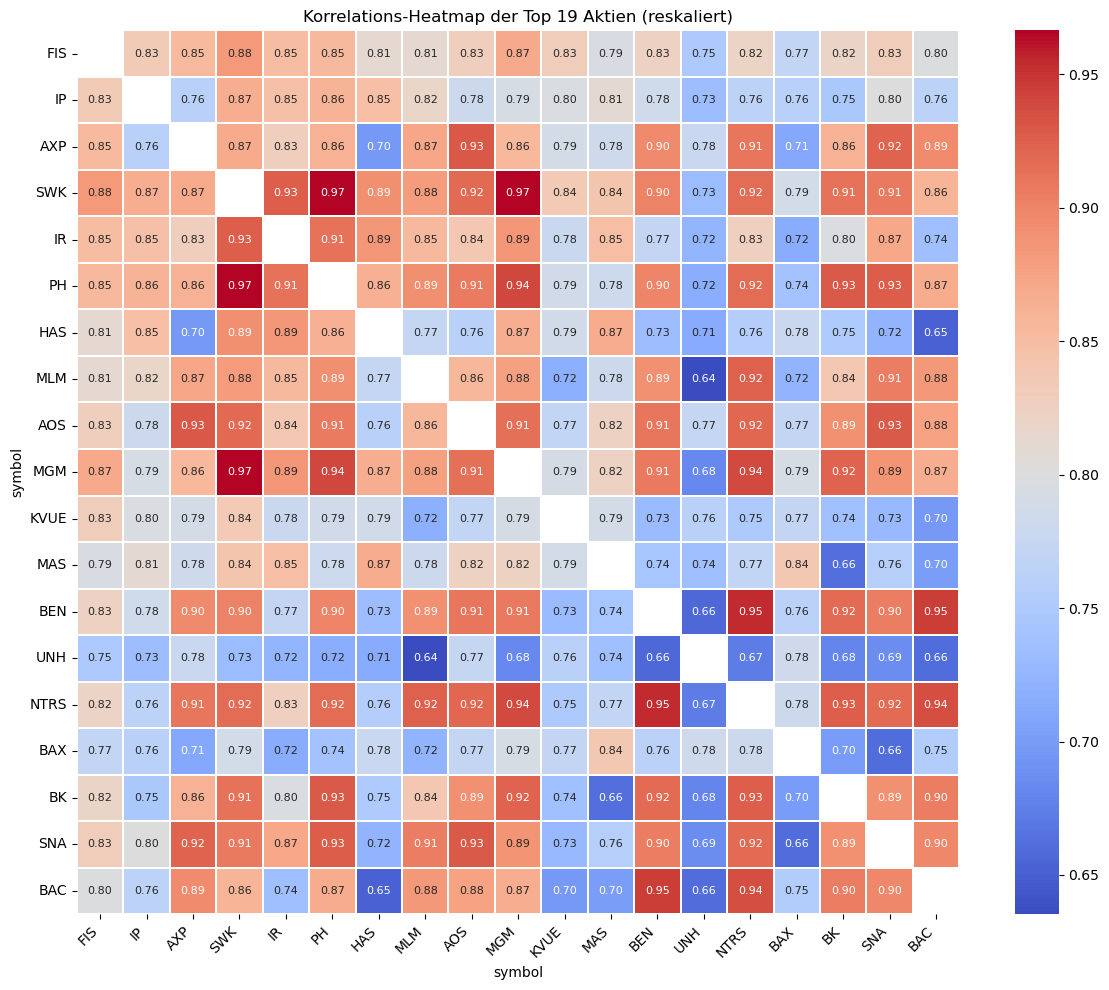

158 stark korrelierte Paare (r > 0.97)


,symbol_1,symbol_2,correlation
0,GOOG,GOOGL,0.999565
1,CFG,USB,0.995162
2,FITB,RF,0.994582
3,SYF,USB,0.994512
4,MTB,RF,0.993797
5,CFG,SYF,0.993756
6,FOX,FOXA,0.993729
7,MTB,TFC,0.993638
8,PNC,TFC,0.993070
9,CFG,TFC,0.992846


Min/Max Off-Diagonal: 0.6352918331386465 0.9664971231614128
Representative symbols: ['FIS', 'IP', 'AXP', 'SWK', 'IR', 'PH', 'HAS', 'MLM', 'AOS', 'MGM', 'KVUE', 'MAS', 'BEN', 'UNH', 'NTRS', 'BAX', 'BK', 'SNA', 'BAC']


In [14]:
prices_wide = out["prices_wide"]
log_prices = np.log(prices_wide)

out = eda.correlation_analysis(
    log_prices,
    strong_threshold=0.97,
    top_n_heatmap=19,
    plot=True,
)

print(f"{len(out['strong_pairs'])} stark korrelierte Paare (r > 0.97)")
display(out["strong_pairs"].head(20))

print("Min/Max Off-Diagonal:", out["vmin_offdiag"], out["vmax_offdiag"])
print("Representative symbols:", list(out["representative_symbols"]))

### 3.4.2. Tägliche Cointegration auf Intraday-Daten

Eine hohe Korrelation zwischen zwei Aktien ist **keine hinreichende Bedingung** für erfolgreiches Pair Trading. Korrelation beschreibt lediglich gleichgerichtete Bewegungen, liefert jedoch keine Aussage darüber, ob sich die Preisreihen **langfristig aneinander binden**. Für Mean-Reversion-Strategien ist stattdessen **Cointegration** entscheidend.

Ziel dieses Schrittes ist es, zu prüfen, ob stark korrelierte Aktienpaare auch **intraday stabil cointegrated** sind. Ein Paar gilt nur dann als trading-relevant, wenn sein Spread nicht driftet, sondern um ein stabiles Gleichgewicht schwankt.

Für jedes zuvor identifizierte **stark korrelierte Paar** wird **tagweise** ein Engle-Granger-Cointegrationstest auf Basis der Intraday-Log-Preise durchgeführt:

- Die Intraday-Daten werden **nach Kalendertagen segmentiert**.
- Pro Tag werden nur Paare berücksichtigt, für die mindestens `min_obs_per_day = 30` **synchronisierte** Beobachtungen vorliegen.
- Fehlende Werte werden entfernt; beide Zeitreihen werden anschließend **zeitlich ausgerichtet** (inner join auf gemeinsame Timestamps).
- Der Engle-Granger-Test liefert ein **p-Value** zur Nullhypothese *„keine Cointegration“*.

Ein niedriges p-Value spricht dafür, dass eine lineare Kombination der beiden Log-Preisreihen stationär ist – die statistische Grundlage für Mean-Reversion-Pair-Trading.

Das Ergebnis wird in `daily_coint_df` gespeichert. Jede Zeile entspricht **einem Paar an einem Handelstag**:

- `date`: Handelstag
- `symbol1`, `symbol2`: Paar-Komponenten
- `pvalue`: Cointegration-p-Value des Tages

Diese Tagesauflösung ermöglicht es anschließend, Cointegration **über die Zeit** zu bewerten (Stabilität/Konsistenz) und nur robuste Paare in die spätere Spread-Analyse bzw. Feature-Generierung zu übernehmen.

In [15]:
strong_pairs = out["strong_pairs"]  # DataFrame mit symbol1/symbol2

min_obs_per_day = 30
p_thresh = 0.05
top_n_pairs = 50

daily_coint_df = eda.compute_daily_cointegration(
    log_prices=log_prices,
    pairs=strong_pairs,
    min_obs_per_day=min_obs_per_day,
    verbose=True,
)

print(f"{len(daily_coint_df)} tägliche Cointegrationseinträge berechnet.")
display(daily_coint_df.head(5))

5688 tägliche Cointegrationseinträge berechnet.


,date,symbol1,symbol2,pvalue
0,2025-11-07 00:00:00+00:00,ADI,TXN,0.486347
1,2025-11-10 00:00:00+00:00,ADI,TXN,0.375418
2,2025-11-11 00:00:00+00:00,ADI,TXN,0.058565
3,2025-11-12 00:00:00+00:00,ADI,TXN,0.018053
4,2025-11-13 00:00:00+00:00,ADI,TXN,0.039208


Nach der tagweisen Berechnung der Cointegration-p-Values (`daily_coint_df`) werden die Resultate auf **Paar-Ebene** verdichtet, um robuste Kandidaten für das Pair-Trading zu identifizieren. Einzelne signifikante Tage können zufällig auftreten; für Trading-Relevanz ist entscheidend, ob Cointegration **konsistent** über viele Tage hinweg auftritt.

Mit `compute_pair_stats(...)` werden die täglichen p-Values je Paar aggregiert. Für jedes Paar entstehen Kennzahlen, die sowohl die *Stärke* als auch die *Stabilität* der Cointegration beschreiben:

- `n_days`: Anzahl Tage mit ausreichenden Intraday-Daten und erfolgreichem Test
- `n_sig_days`: Anzahl Tage mit signifikantem Ergebnis (`pvalue < p_thresh`)
- `mean_p`, `std_p`, `min_p`, `max_p`: Verteilung der p-Values über die Zeit
- `consistency = n_sig_days / n_days`: Anteil signifikant cointegrated Tage (Robustheitsmaß)

Die Kennzahl **consistency** ist im Kontext Intraday-Pairs-Trading besonders wichtig, da sie misst, wie häufig das Paar tatsächlich eine stationäre Beziehung zeigt – und damit, wie zuverlässig ein Mean-Reversion-Spread erwartet werden kann.

Anschließend werden zwei sinnvolle Ranglisten erstellt, weil „gute“ Cointegration je nach Zielsetzung unterschiedlich definiert werden kann:

1. **Ranking nach Robustheit (Konsistenz):**  
   Sortiert nach `consistency` (absteigend) und als Tie-Breaker nach `mean_p` (aufsteigend).  
   Diese Liste bevorzugt Paare, die über viele Tage hinweg signifikant cointegrated sind.

2. **Ranking nach statistischer Stärke (mean_p):**  
   Sortiert nach `mean_p` (aufsteigend).  
   Diese Liste findet Paare mit im Mittel sehr niedrigen p-Values, kann aber Paare enthalten, die nur an wenigen Tagen beobachtet wurden.

Für die Top-Paare wird anschließend der zeitliche Verlauf der p-Values geplottet. 
Die y-Achse wird invertiert, damit „besser“ (kleineres p) visuell oben liegt. So lässt sich auf einen Blick erkennen, ob ein Paar stabil unterhalb der Schwelle bleibt oder ob die Cointegration nur sporadisch auftritt.

Um die Struktur der besten Paare zu verstehen, wird aus den Top-Kandidaten ein Graph konstruiert:

- **Knoten:** einzelne Aktien
- **Kanten:** cointegrated Paare
- **Kantenlabel:** `mean_p | consistency`

Der Netzwerkplot hilft dabei zu erkennen,
- ob sich Cluster bilden (z.B. sektorspezifische Gruppen),
- ob einzelne Aktien als „Hub“ in vielen cointegrated Beziehungen auftreten,
- und ob die besten Paare isoliert oder Teil eines größeren Zusammenhangs sind.

Diese Auswertung dient sowohl der Modellinterpretation als auch als Plausibilitätscheck: Ein stark sektorlastiges Netzwerk kann z.B. auf gemeinsame Makrofaktoren hindeuten, was später bei Risiko- und Diversifikationsüberlegungen relevant ist.

Anzahl Paare mit täglichen Cointegrationsdaten: 158
Top 50 Paare nach Konsistenz und mittlerem p-Wert:


,symbol1,symbol2,n_days,n_sig_days,mean_p,std_p,min_p,max_p,consistency
0,KEY,LUV,36,17,0.221251,0.317446,2.394035e-09,0.943319,0.472222
1,HBAN,LUV,36,15,0.206322,0.303862,5.145057e-08,0.962041,0.416667
2,LUV,RF,36,15,0.250203,0.265086,1.123249e-06,0.951464,0.416667
3,AEP,CMS,36,14,0.209693,0.242445,4.777067e-06,0.859479,0.388889
4,KEY,USB,36,14,0.238790,0.277604,1.674863e-05,0.918903,0.388889
5,HLT,MAR,36,14,0.260118,0.309266,1.521327e-04,0.862007,0.388889
6,CTSH,KEY,36,14,0.283488,0.341574,9.008061e-07,0.965959,0.388889
7,GS,IVZ,36,13,0.244307,0.312226,9.230291e-05,0.967266,0.361111
8,KEY,TFC,36,13,0.249793,0.265543,2.520622e-06,0.974611,0.361111
9,KEY,MTB,36,13,0.260481,0.285451,4.469637e-10,0.885525,0.361111



Top 50 Paare nach bestem (niedrigstem) mean_p:


,symbol1,symbol2,n_days,n_sig_days,mean_p,std_p,min_p,max_p,consistency
0,DECK,EA,36,12,0.202035,0.227707,1.718738e-07,0.852017,0.333333
1,HBAN,LUV,36,15,0.206322,0.303862,5.145057e-08,0.962041,0.416667
2,AEP,CMS,36,14,0.209693,0.242445,4.777067e-06,0.859479,0.388889
3,HBAN,TFC,36,9,0.214617,0.239397,2.052282e-06,0.880964,0.250000
4,HBAN,SYF,36,11,0.217979,0.255475,5.304177e-05,0.949321,0.305556
5,HBAN,USB,36,12,0.218393,0.240009,1.485155e-03,0.991490,0.333333
6,KEY,LUV,36,17,0.221251,0.317446,2.394035e-09,0.943319,0.472222
7,HBAN,KEY,36,9,0.221710,0.217337,1.458663e-03,0.873800,0.250000
8,CTSH,RF,36,12,0.235739,0.284557,2.635785e-05,0.989442,0.333333
9,CTSH,GM,36,11,0.236550,0.264804,2.569574e-04,0.918022,0.305556


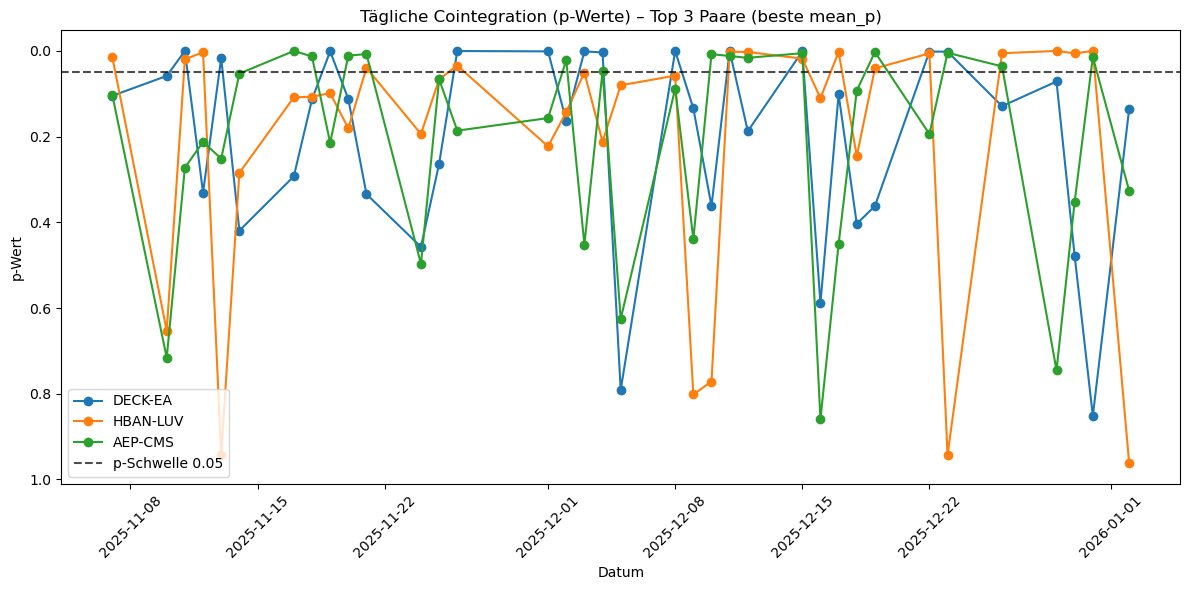

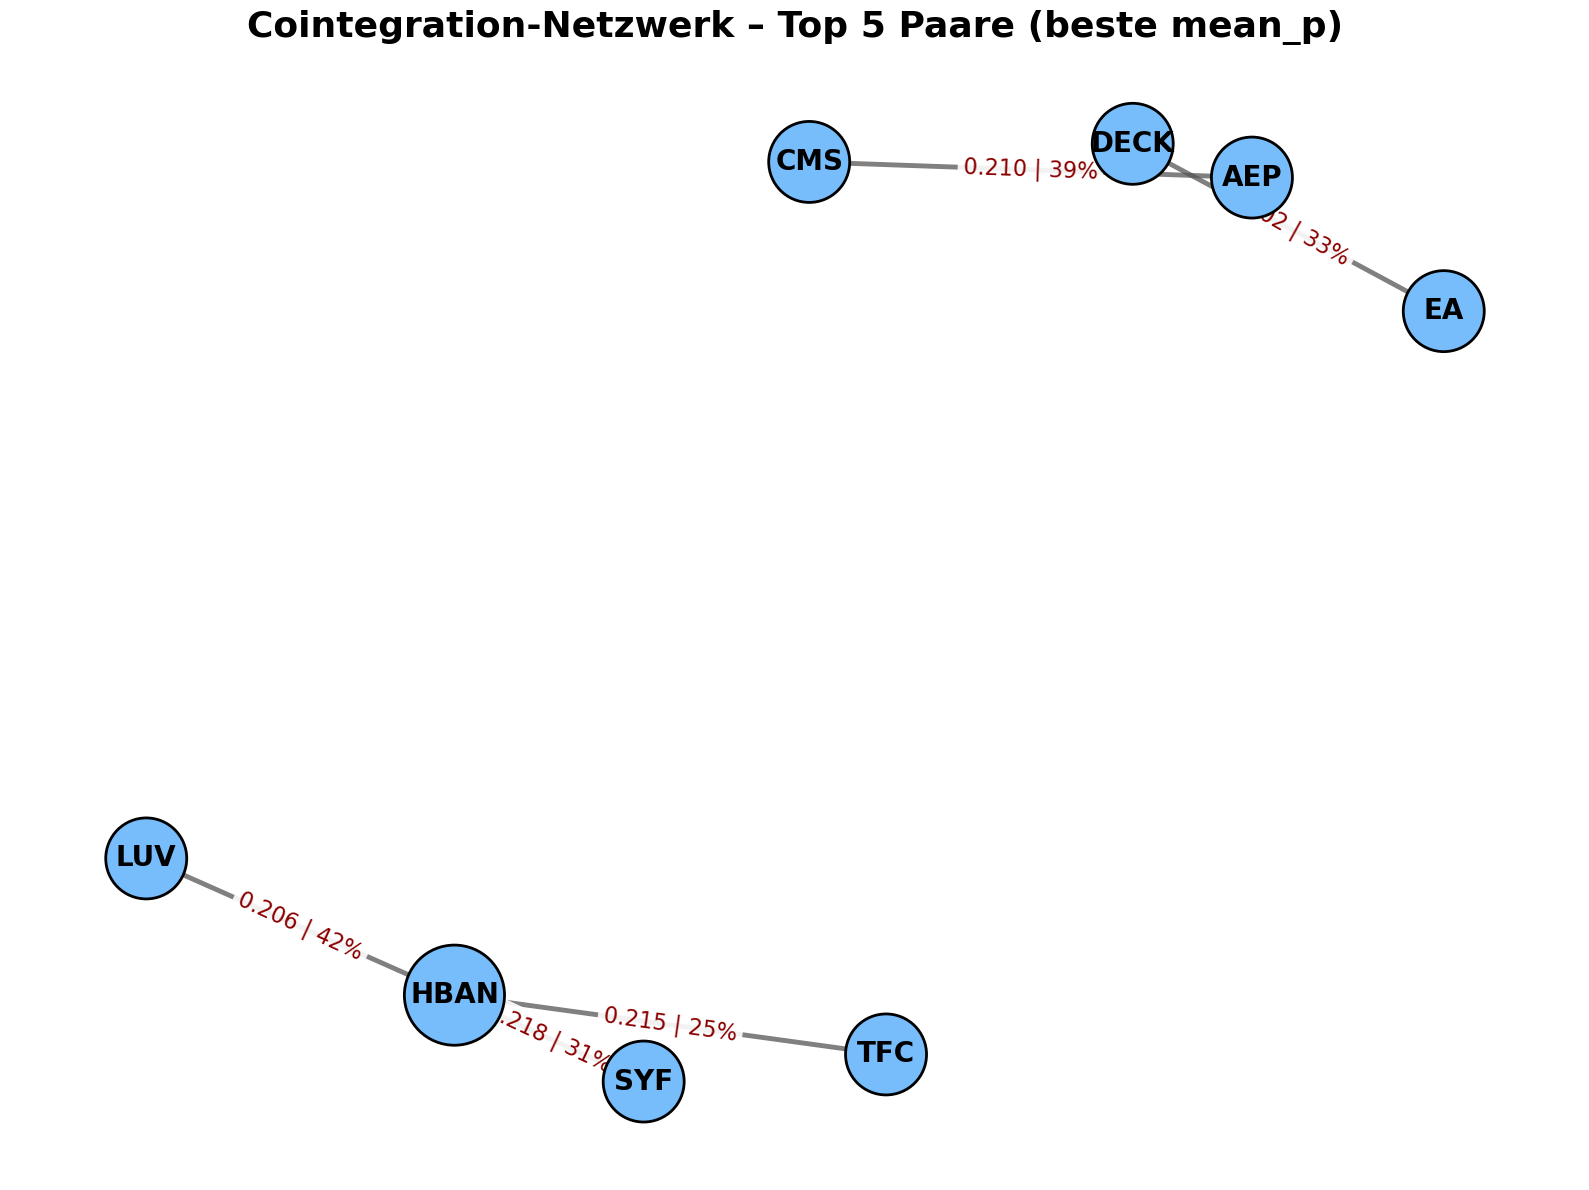

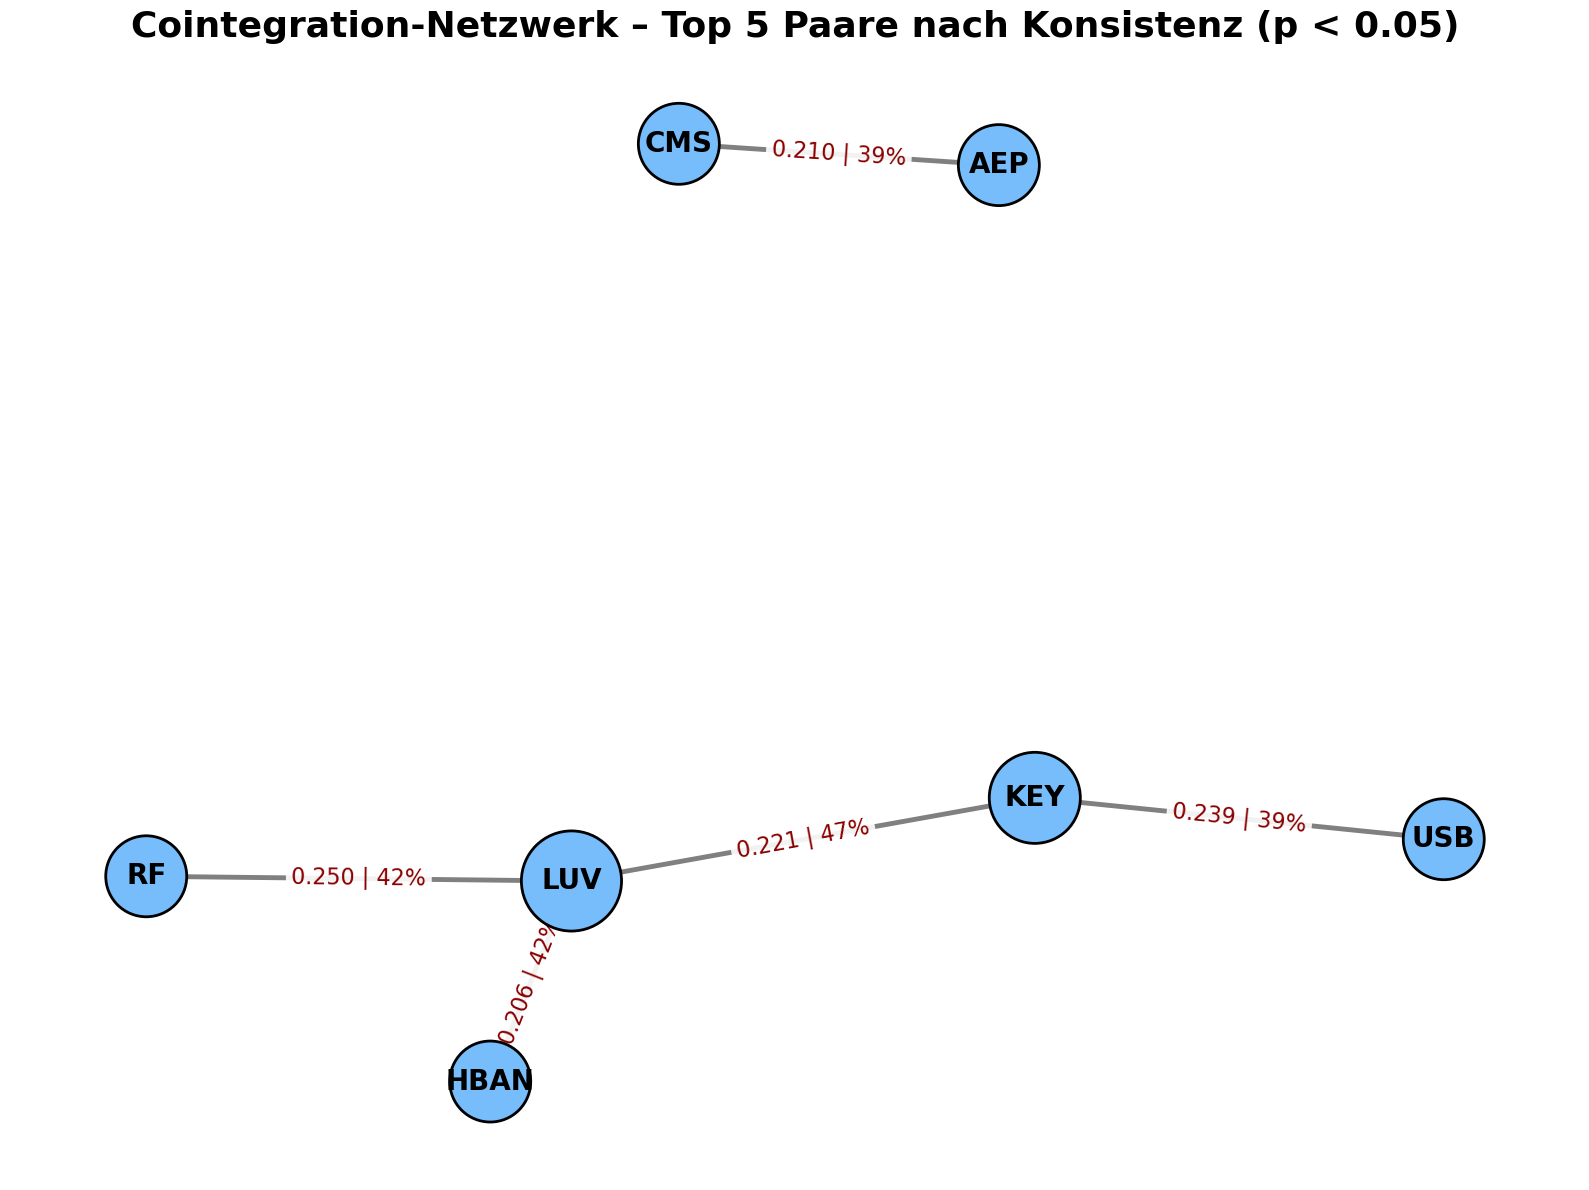

In [16]:
pair_stats = eda.compute_pair_stats(daily_coint_df, p_thresh=p_thresh)
top_pairs_consistency, top_pairs_mean_p = eda.rank_pairs(pair_stats, top_n=top_n_pairs)

print(f"Anzahl Paare mit täglichen Cointegrationsdaten: {len(pair_stats)}")
print(f"Top {top_n_pairs} Paare nach Konsistenz und mittlerem p-Wert:")
display(top_pairs_consistency)

print(f"\nTop {top_n_pairs} Paare nach bestem (niedrigstem) mean_p:")
display(top_pairs_mean_p)

# Plot p-values (Top nach mean_p)
top_n_plot = 3
fig = eda.plot_daily_pvalues(
    daily_coint_df,
    top_pairs=top_pairs_mean_p,
    p_thresh=p_thresh,
    top_n_plot=top_n_plot,
    title=f"Tägliche Cointegration (p-Werte) – Top {top_n_plot} Paare (beste mean_p)",
)
plt.show()

# Netzwerkplots
top_n_network = 5

fig = eda.plot_coint_network(
    top_pairs_mean_p.head(top_n_network),
    title=f"Cointegration-Netzwerk – Top {top_n_network} Paare (beste mean_p)"
)
plt.show()

fig = eda.plot_coint_network(
    top_pairs_consistency.head(top_n_network),
    title=f"Cointegration-Netzwerk – Top {top_n_network} Paare nach Konsistenz (p < {p_thresh})"
)
plt.show()

Nach der Auswahl der robustesten cointegrated Paare wird der **Spread** explizit analysiert. Im Pair-Trading ist der Spread die zentrale Trading-Größe: Nur wenn der Spread **stationär** ist und um einen stabilen Mittelwert schwankt, ist Mean Reversion als Signalquelle plausibel.

Da die Preise im Projekt als **Log-Preise** vorliegen, wird auch der Spread in Log-Skala berechnet:

$$
\text{spread}_t = \log(P^{(1)}_t) - \log(P^{(2)}_t) = \log\left(\frac{P^{(1)}_t}{P^{(2)}_t}\right)
$$

Damit entspricht der Spread einer Log-Preisratio und ist direkt interpretierbar als relative Preisabweichung.

Für die Spread-Auswertung werden die **Top-Paare nach Konsistenz** verwendet. In der folgenden Zelle werden die ersten `top_n = 3` Paare aus `top_pairs_consistency` ausgewählt.

Mit `compute_daily_spread_stats(...)` werden pro Paar und Tag grundlegende Kennzahlen des Intraday-Spreads berechnet:

- `mean_spread`: durchschnittlicher Spread innerhalb des Tages
- `std_spread`: Intraday-Volatilität des Spreads
- `min_spread`, `max_spread`: Extremwerte (Bandbreite) des Tages

Diese Kennzahlen dienen dazu, die Spread-Dynamik über Zeit zu verstehen (Drift vs. stabile Reversion) und später robuste Normalisierung/Signalbildung (z.B. Z-Score) zu unterstützen.

`plot_daily_mean_spreads(...)` zeigt die zeitliche Entwicklung des Tagesmittelwerts des Spreads je Paar. Zusätzlich wird der Gesamtmittelwert als Referenzlinie geplottet. Damit lässt sich prüfen, ob sich der Spread-Mittelwert über die Zeit verschiebt (Regimewechsel/Drift) oder relativ stabil bleibt.

`plot_intraday_spreads_last_day(...)` betrachtet ausschließlich den **letzten verfügbaren Handelstag** und zeigt den intraday Verlauf des Spreads inklusive Tagesmittelwert. Das ist besonders relevant für das Intraday-Setup, weil hier sichtbar wird, ob der Spread innerhalb eines Tages tatsächlich schwankt und potenziell kurzfristige Mean-Reversion-Gelegenheiten liefert.

Zusätzlich werden beispielhaft die beiden Preisreihen des Paares am letzten Tag geplottet, jedoch **exponentiert** (zurück auf lineare Preise) und anschließend **auf 1 normalisiert** (Startwert = 1). So lässt sich visuell prüfen, ob die beiden Assets intraday gemeinsam laufen und ob Abweichungen plausibel sind. Diese Darstellung ist ein Plausibilitätscheck, der Spread-Bewegungen in den zugrundeliegenden Preisverläufen verankert.

,date,symbol1,symbol2,mean_spread,std_spread,min_spread,max_spread
0,2025-11-07 00:00:00+00:00,HBAN,LUV,-0.712654,0.006772,-0.729200,-0.699745
1,2025-11-10 00:00:00+00:00,HBAN,LUV,-0.728524,0.007512,-0.751517,-0.719261
2,2025-11-11 00:00:00+00:00,HBAN,LUV,-0.703301,0.006719,-0.727287,-0.694559
3,2025-11-12 00:00:00+00:00,HBAN,LUV,-0.726212,0.008716,-0.740400,-0.703844
4,2025-11-13 00:00:00+00:00,HBAN,LUV,-0.738871,0.004386,-0.748369,-0.726697


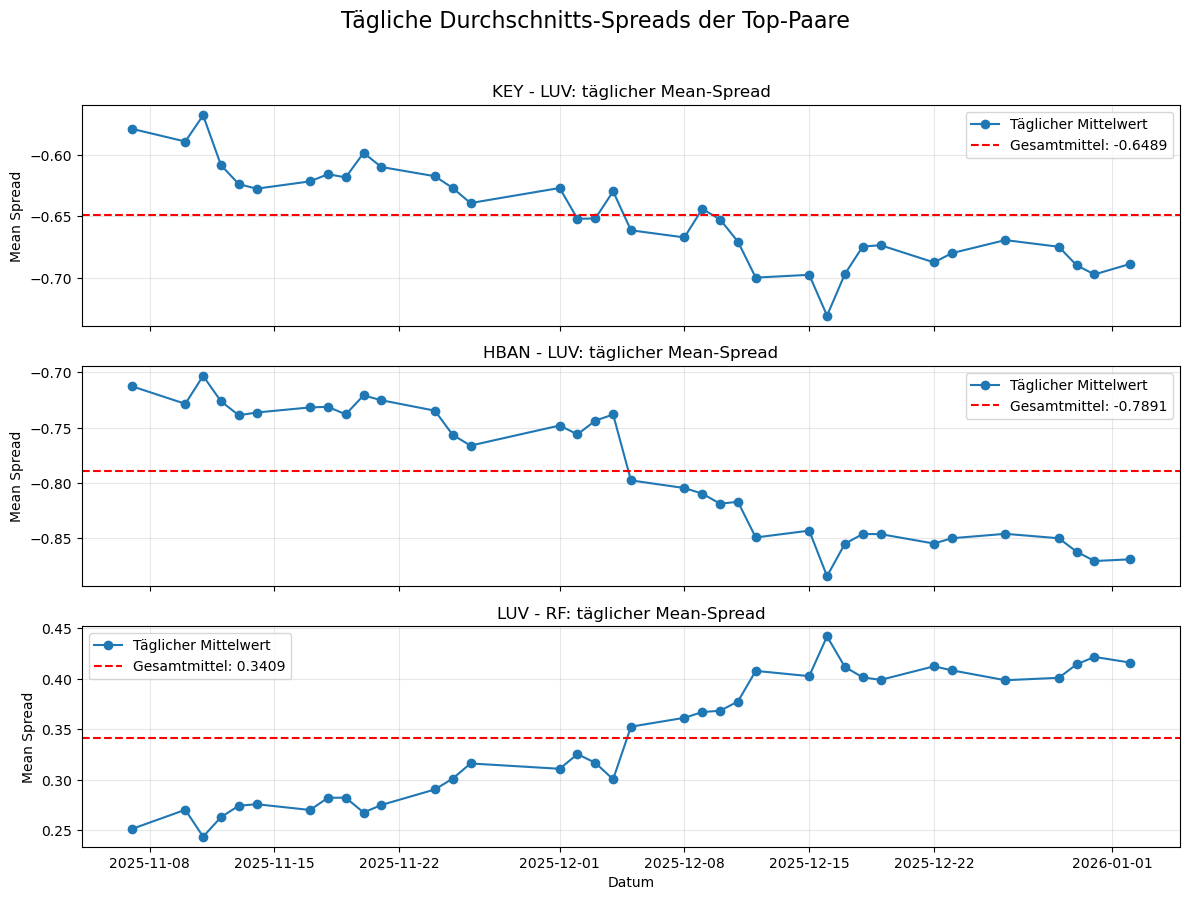

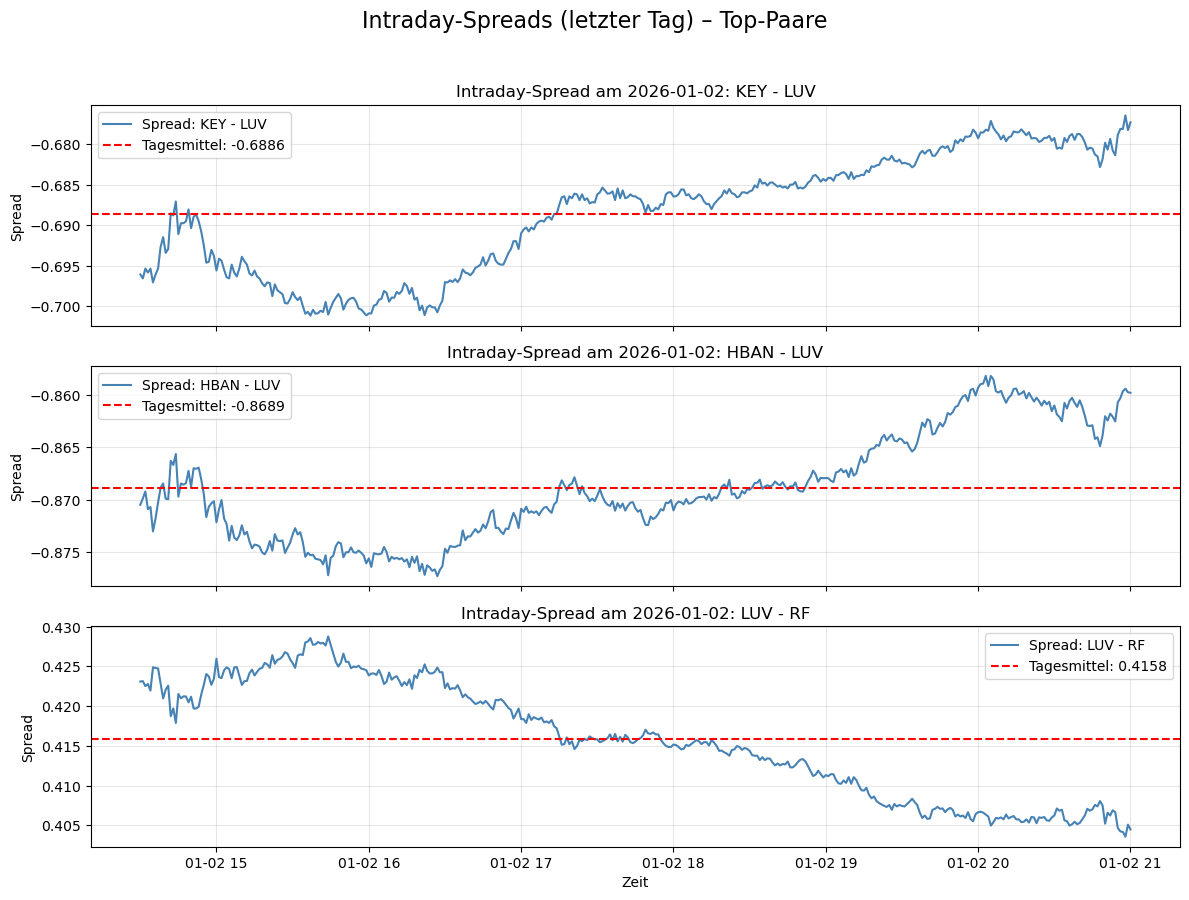

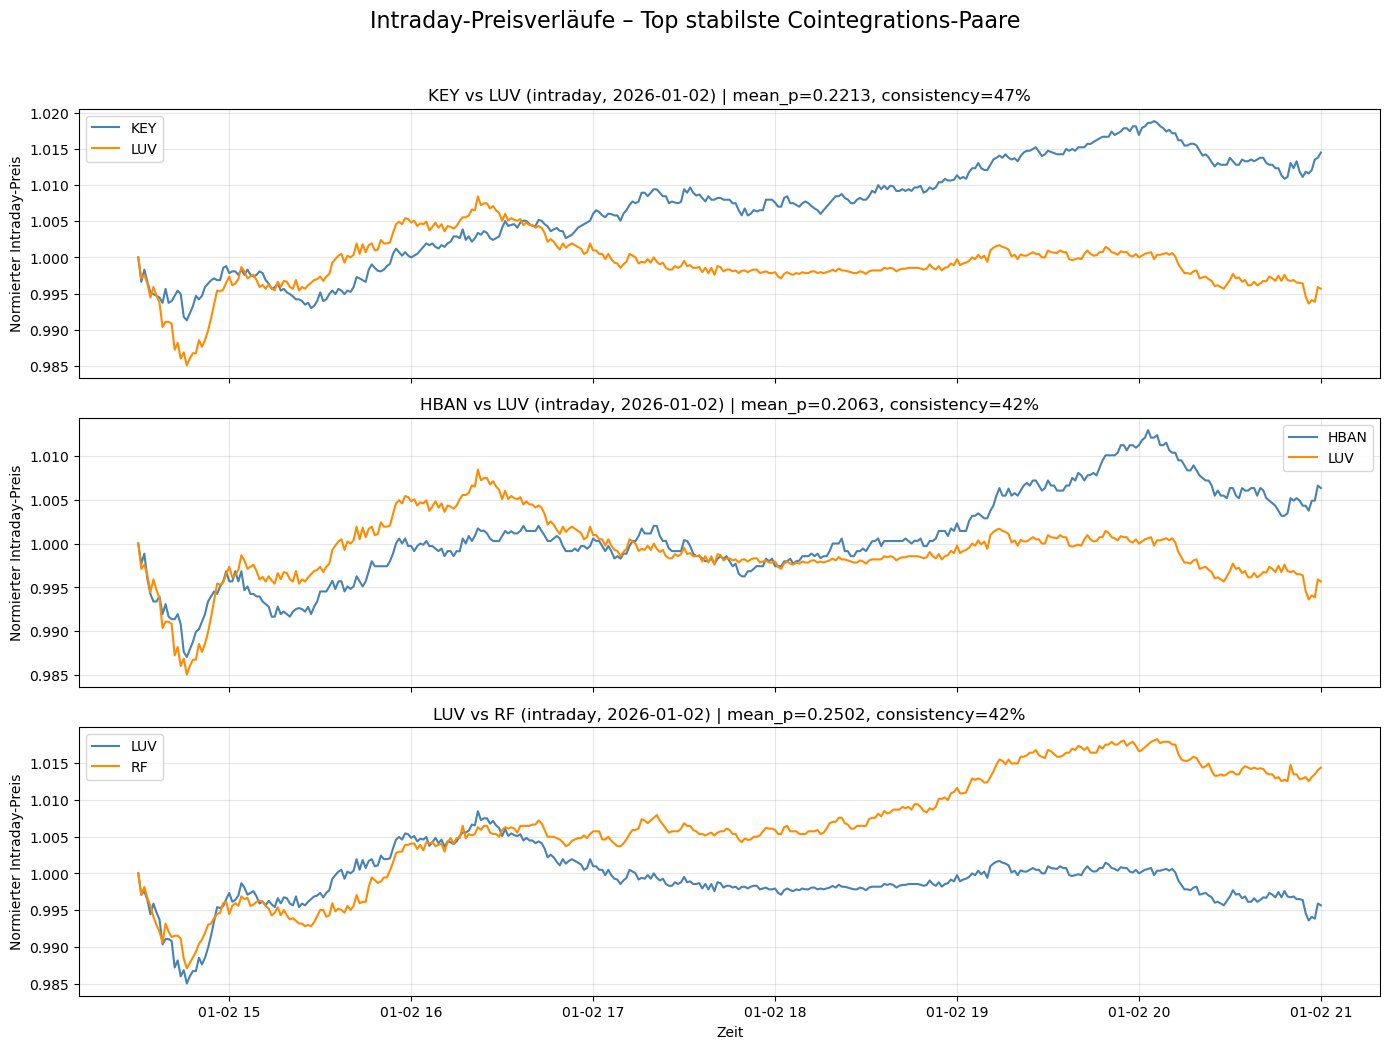

In [17]:
# Spreads vom letzten Tag
top_n = 3
pairs_to_plot_df = top_pairs_consistency.head(top_n)[["symbol1", "symbol2"]]

daily_spread_df = eda.compute_daily_spread_stats(log_prices, pairs_to_plot_df)
display(daily_spread_df.head())

fig = eda.plot_daily_mean_spreads(daily_spread_df, pairs_to_plot_df)
plt.show()

fig = eda.plot_intraday_spreads_last_day(log_prices, pairs_to_plot_df)
plt.show()

fig = eda.plot_intraday_prices_last_day(log_prices, top_pairs=top_pairs_consistency, top_n=top_n)
plt.show()

### 3.3.3. Technischen Indikatoren

In diesem Schritt wird untersucht, wie ähnlich sich die ausgewählten Trading-Paare **hinsichtlich technischer Indikatoren** verhalten. Ziel ist es, über die reine Preis- und Spreadanalyse hinauszugehen und zu prüfen, ob Paare auch auf Indikatorebene konsistente Muster aufweisen.

Für die jeweils besten Paare aus zwei Selektionsstrategien  
- **Consistency-basierte Paare**  
- **Mean-p-value-basierte Paare**  

werden folgende technische Indikatoren berechnet und verglichen:
- Simple Moving Average (SMA, 20)
- Exponential Moving Average (EMA, 20)
- Relative Strength Index (RSI, 14)
- Volatilität (Rolling Std, 20)

Die Funktion `indicator_similarity_for_pairs` führt dabei mehrere Schritte aus:
1. Berechnung der Indikatoren auf Symbol-Ebene
2. Aggregation der Indikator-Zeitreihen auf Paarebene
3. Ermittlung von **Korrelationsmatrizen** zwischen allen beteiligten Symbolen
4. Transformation der Korrelationen in **Distanzmatrizen** zur späteren Clusteranalyse
5. Erfassung von Metadaten wie Anzahl der Symbole und gemeinsamer gültiger Startzeitpunkt

Zusätzlich wird eine kompakte Korrelationsübersicht für die Top-Paare erzeugt, um erste strukturelle Zusammenhänge auf Indikatorebene sichtbar zu machen.

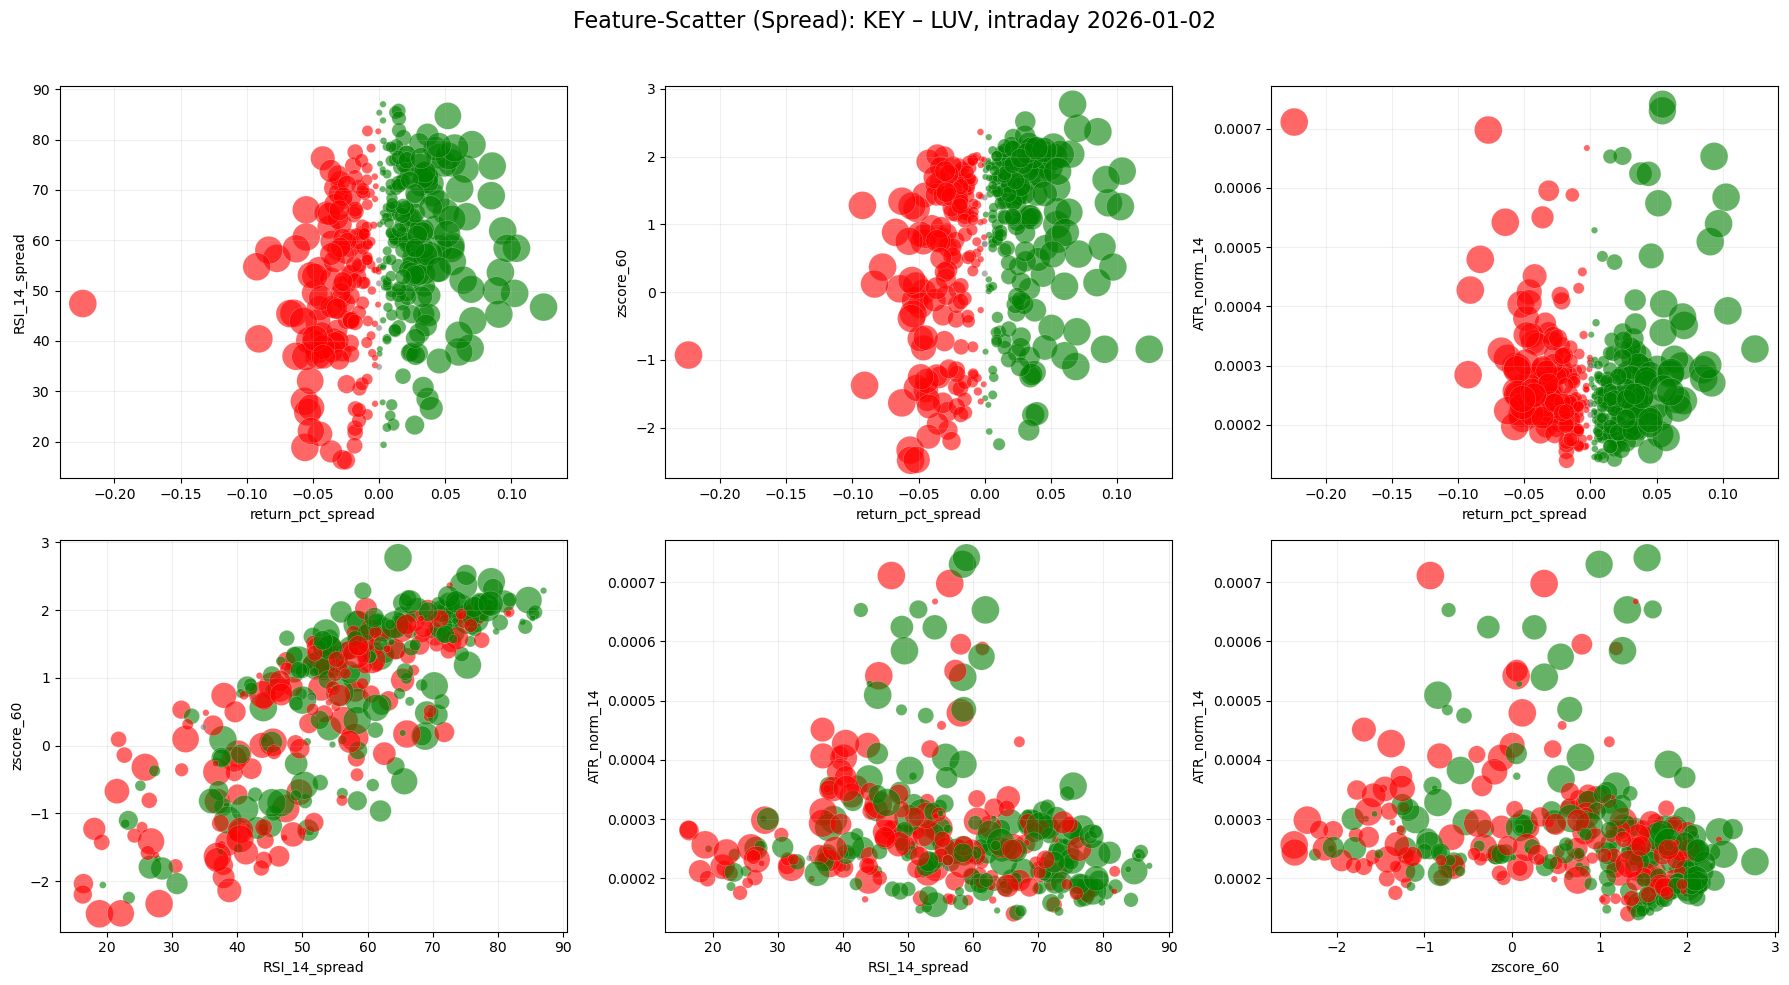

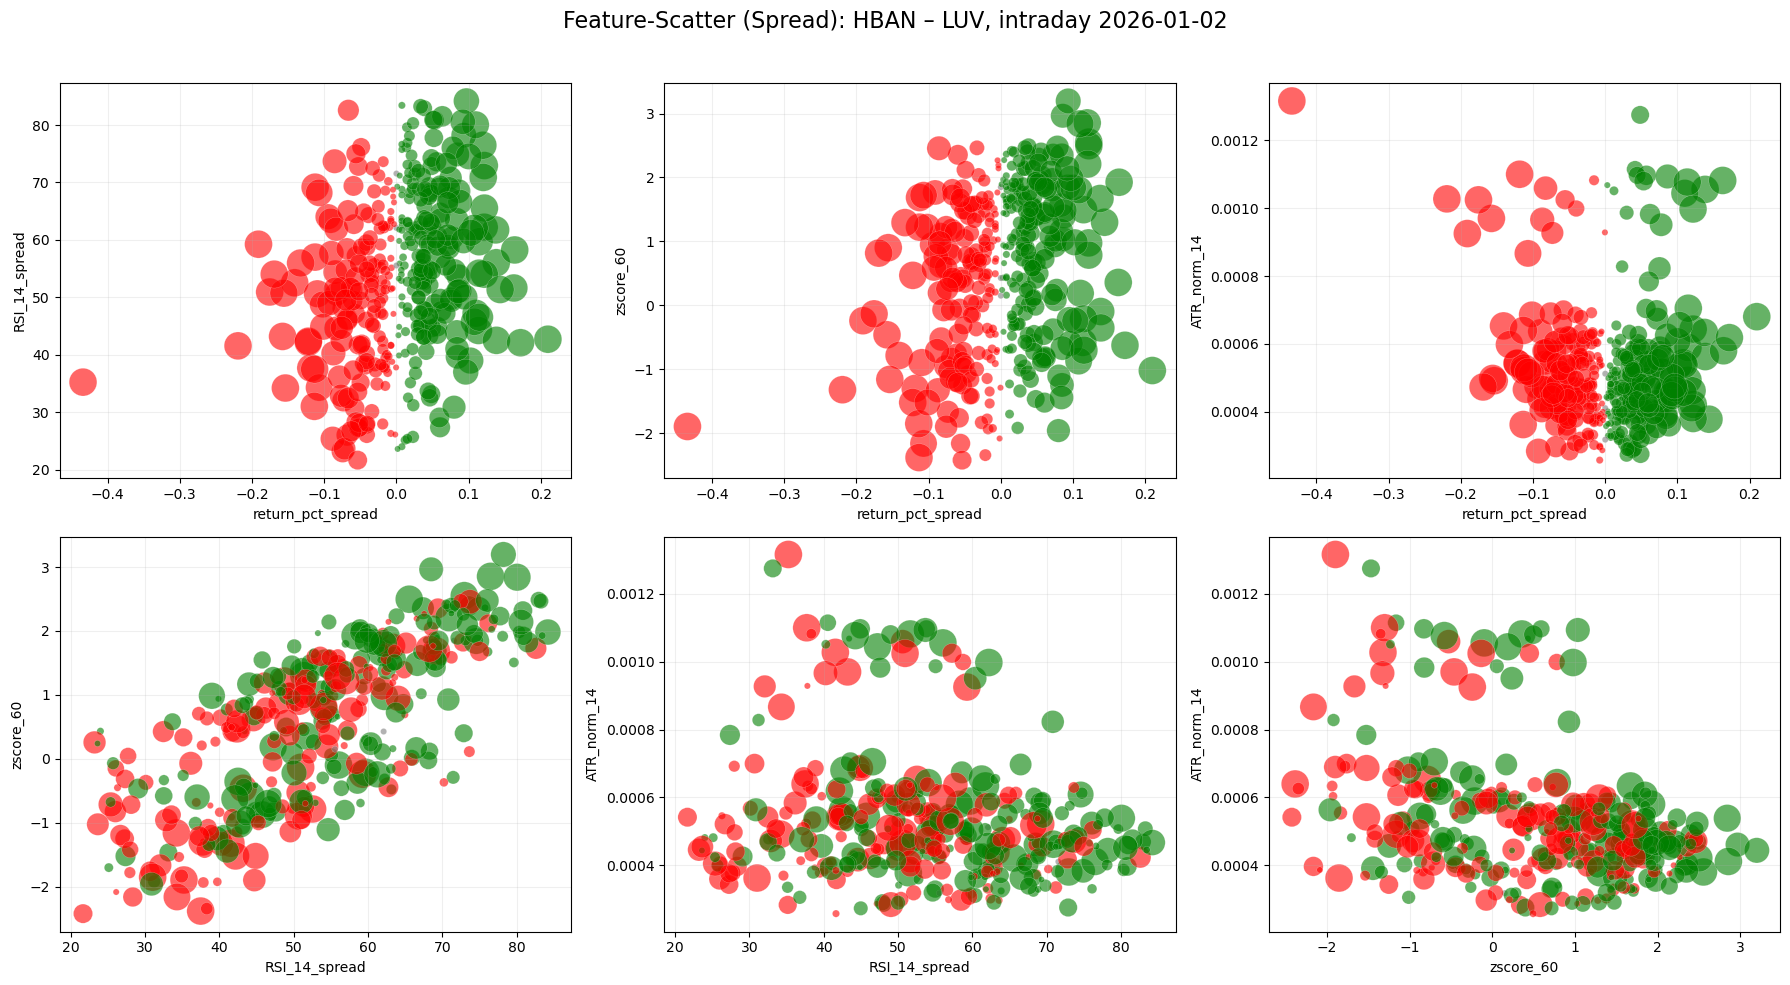

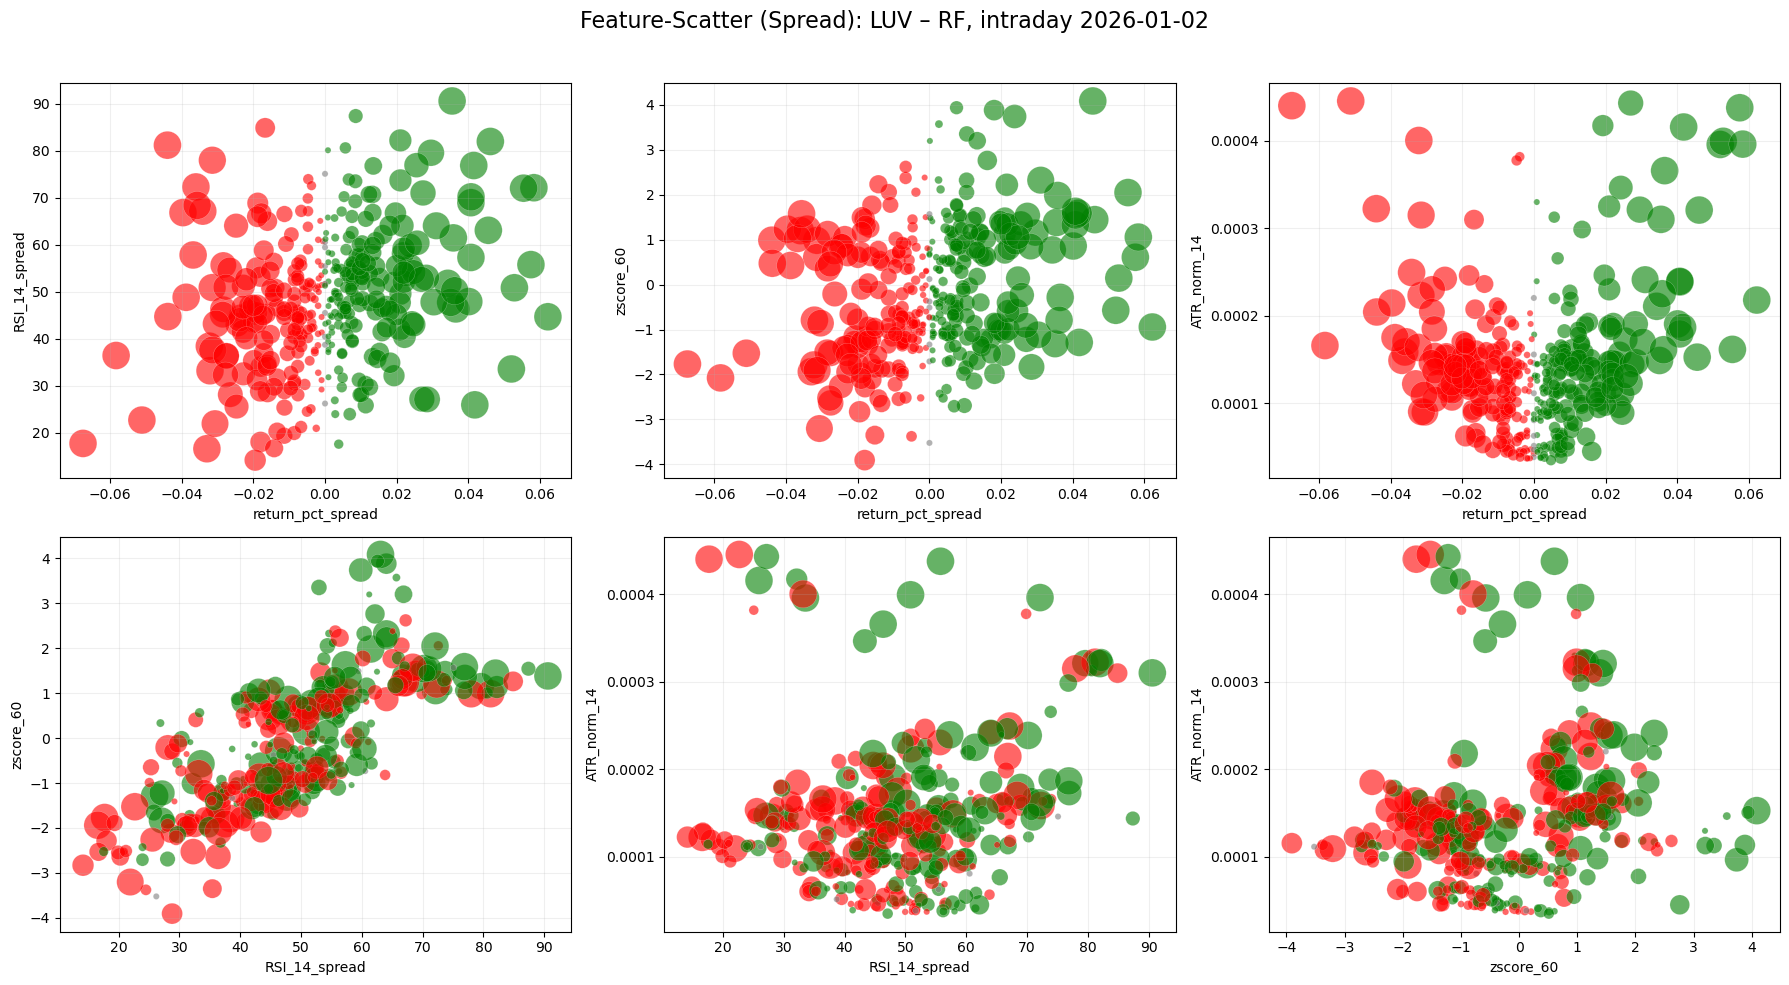

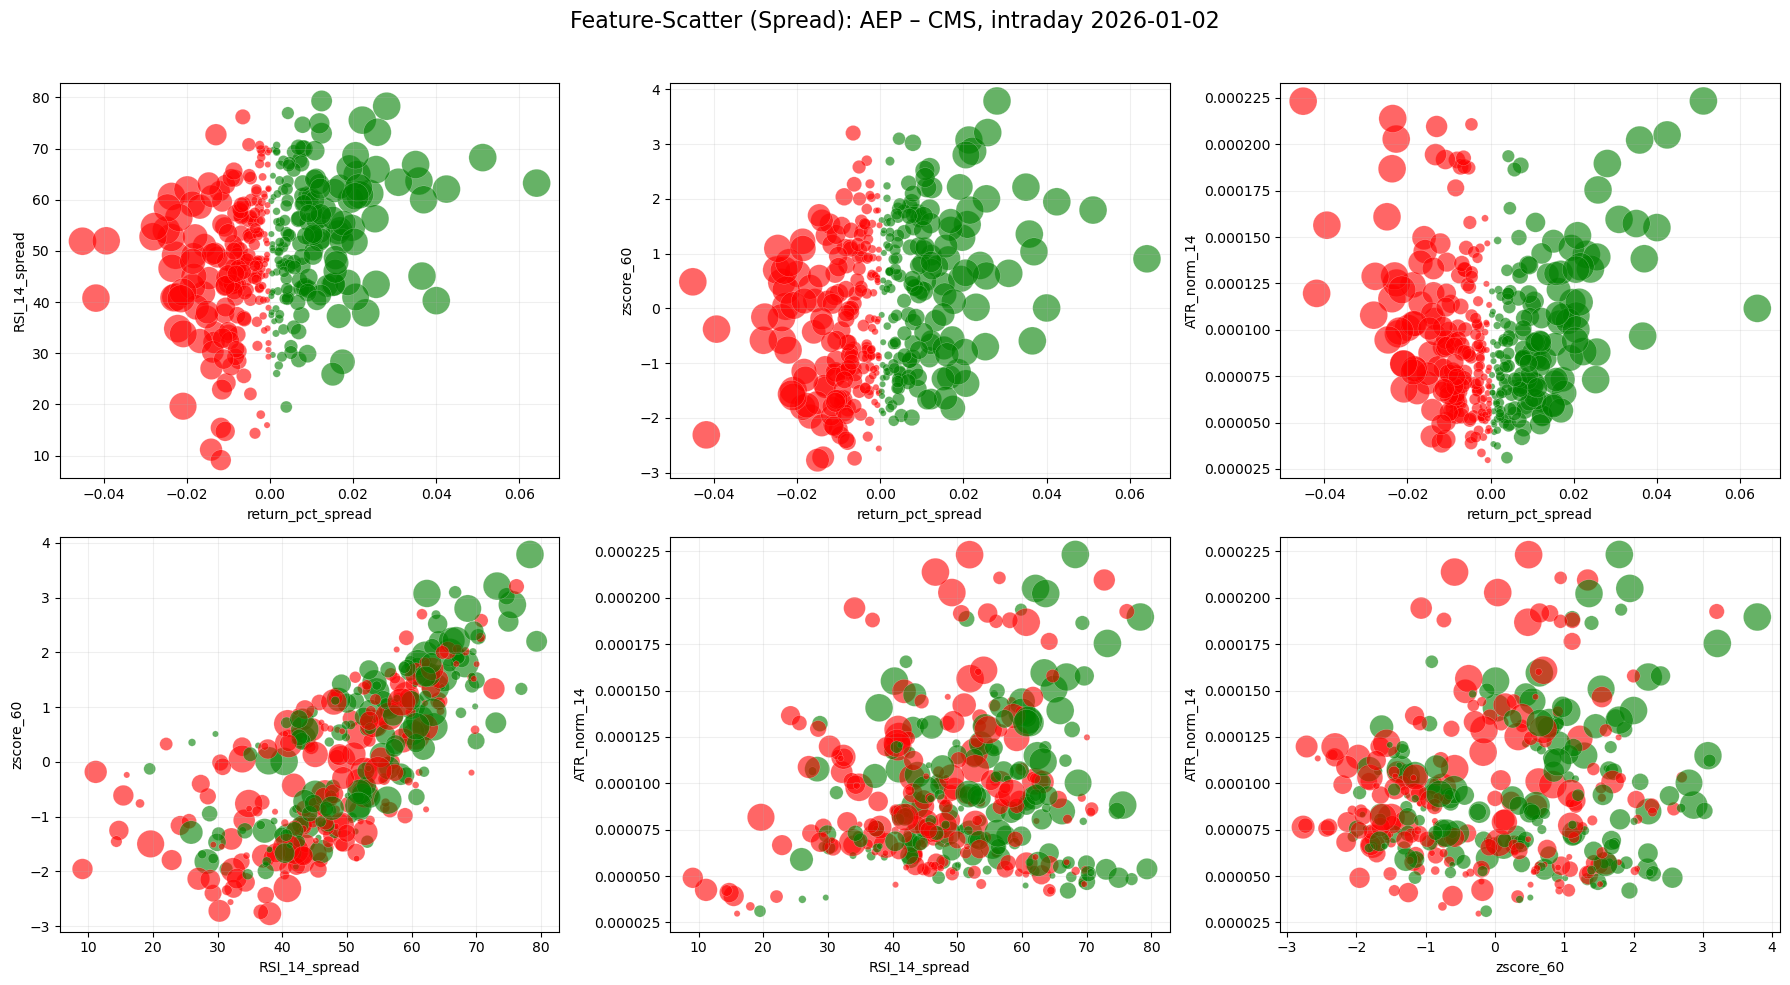

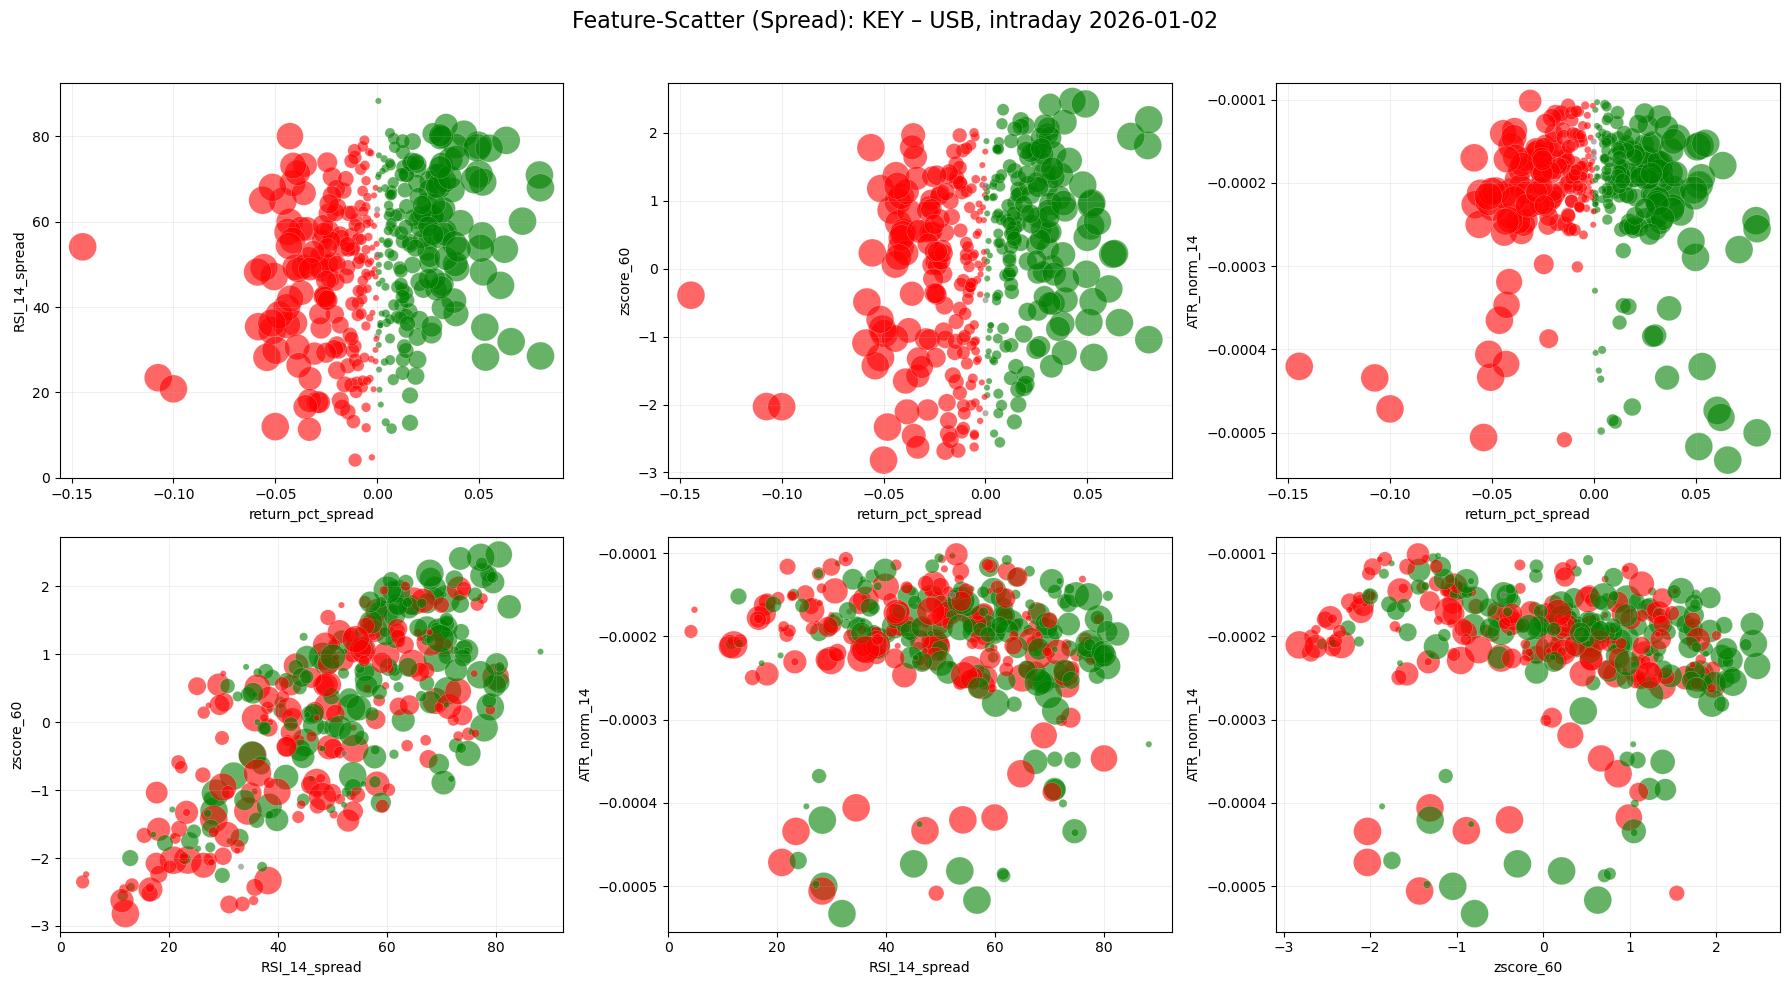

In [18]:
# Multivariate Feature-Struktur von Spread-Indikatoren (Intraday)

# Paare (aus vorheriger EDA)
if "top_pairs_consistency" in globals():
    pairs_df = top_pairs_consistency
elif "top_pairs_mean_p" in globals():
    pairs_df = top_pairs_mean_p
else:
    raise NameError("Keine top_pairs_* Tabelle gefunden.")

pairs = pairs_df[["symbol1", "symbol2"]].head(5).values.tolist()

# Letzter Handelstag
last_day = log_prices.index.normalize().max()
intraday = log_prices.loc[log_prices.index.normalize() == last_day]

RSI_W, Z_W, ATR_W = 14, 60, 14

axis_features = [
    "return_pct_spread",
    f"RSI_{RSI_W}_spread",
    f"zscore_{Z_W}",
    f"ATR_norm_{ATR_W}",
]

pairs_axes = [
    (axis_features[0], axis_features[1]),
    (axis_features[0], axis_features[2]),
    (axis_features[0], axis_features[3]),
    (axis_features[1], axis_features[2]),
    (axis_features[1], axis_features[3]),
    (axis_features[2], axis_features[3]),
]

for s1, s2 in pairs:

    if s1 not in intraday.columns or s2 not in intraday.columns:
        continue

    prices = intraday[[s1, s2]].dropna()
    if len(prices) < 60:
        continue

    beta, _ = np.polyfit(prices[s2].values, prices[s1].values, 1)
    spread = prices[s1] - beta * prices[s2]

    df = pd.DataFrame(index=spread.index)
    df["spread"] = spread

    prev_abs = df["spread"].shift(1).abs().replace(0, np.nan)
    df["return_pct_spread"] = (df["spread"] - df["spread"].shift(1)) / prev_abs * 100

    tmp = pd.concat([df["spread"], df["spread"]], axis=1)
    tmp.columns = ["SPREAD", "SPREAD_DUMMY"]
    df[f"RSI_{RSI_W}_spread"] = features.rsi(tmp, window=RSI_W)["SPREAD"]

    roll_mean = df["spread"].rolling(Z_W, min_periods=1).mean()
    roll_std = df["spread"].rolling(Z_W, min_periods=1).std().replace(0, np.nan)
    df[f"zscore_{Z_W}"] = (df["spread"] - roll_mean) / roll_std

    atr = df["spread"].diff().abs().rolling(ATR_W, min_periods=1).mean()
    df[f"ATR_norm_{ATR_W}"] = atr / roll_mean.replace(0, np.nan)

    df["dir"] = np.sign(df["spread"].diff()).map({1: "up", -1: "down"}).fillna("flat")
    abs_move = df["return_pct_spread"].abs().fillna(0)
    scale = np.nanpercentile(abs_move, 90) or 1.0
    df["size"] = np.clip(abs_move / scale * 400, 20, 400)

    plot_df = df[axis_features].replace([np.inf, -np.inf], np.nan).dropna()
    if plot_df.empty:
        continue

    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.flatten()

    for ax, (x, y) in zip(axes, pairs_axes):
        ax.scatter(
            plot_df[x],
            plot_df[y],
            s=df.loc[plot_df.index, "size"],
            c=df.loc[plot_df.index, "dir"].map({"up": "green", "down": "red", "flat": "gray"}),
            alpha=0.6,
            edgecolors="w",
            linewidth=0.2,
        )
        ax.set_xlabel(x)
        ax.set_ylabel(y)
        ax.grid(alpha=0.2)

    plt.suptitle(
        f"Feature-Scatter (Spread): {s1} – {s2}, intraday {last_day.date()}",
        fontsize=16,
    )
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()


In [19]:
top_n_pairs = 50
top_n_pairs_table = 10
n_clusters = 6
linkage = "average"

meta_cons, corr_cons, dist_cons = eda.indicator_similarity_for_pairs(
    top_pairs_consistency,
    prices_wide=prices_wide,
    log_prices=log_prices,
    top_n=top_n_pairs
)

meta_meanp, corr_meanp, dist_meanp = eda.indicator_similarity_for_pairs(
    top_pairs_mean_p,
    prices_wide=prices_wide,
    log_prices=log_prices,
    top_n=top_n_pairs
)

print("Consistency:", meta_cons["n_symbols"], "symbols | valid_start:", meta_cons["valid_start"])
print("Mean-p     :", meta_meanp["n_symbols"], "symbols | valid_start:", meta_meanp["valid_start"])

display(eda.pair_corr_summary(top_pairs_consistency, corr_cons["SMA_20"], top_n=10))

Consistency: 34 symbols | valid_start: 2025-11-07 14:50:00+00:00
Mean-p     : 41 symbols | valid_start: 2025-11-07 14:50:00+00:00


,symbol1,symbol2,indicator_corr
0,KEY,LUV,0.980297
1,HBAN,LUV,0.968890
2,LUV,RF,0.975442
3,AEP,CMS,0.972691
4,KEY,USB,0.987634
5,HLT,MAR,0.975028
6,CTSH,KEY,0.971907
7,GS,IVZ,0.978898
8,KEY,TFC,0.985075
9,KEY,MTB,0.983215


Basierend auf den zuvor berechneten Distanzmatrizen werden die Paare nun mithilfe von **agglomerativem hierarchischem Clustering** gruppiert. Ziel ist es, Paare zu identifizieren, die sich bezüglich ihrer technischen Indikatoren besonders ähnlich verhalten.

Das Clustering wird separat durchgeführt für:
- Consistency-basierte Paare
- Mean-p-value-basierte Paare

und jeweils für die folgenden Indikatoren:
- SMA (20)
- EMA (20)
- RSI (14)
- Volatilität (20)

Dabei gilt:
- Die Distanzmatrizen dienen als Input für das Clustering
- Die Anzahl der Cluster ist fest vorgegeben
- Als Linkage-Methode wird `average` verwendet, um robuste Clusterstrukturen zu erhalten

Die resultierenden Clusterlabels werden gesammelt und anschließend in einer Übersichtstabelle zusammengeführt. Diese Tabelle erlaubt einen schnellen Vergleich der Clusterverteilungen über:
- unterschiedliche Indikatoren
- unterschiedliche Paarselektionsmethoden

Damit wird sichtbar, ob bestimmte Indikatoren zu stabileren oder homogeneren Gruppierungen führen.

In [20]:
labels = {
    "SMA_cons": eda.agglom_labels_from_dist(dist_cons["SMA_20"], n_clusters, linkage=linkage),
    "EMA_cons": eda.agglom_labels_from_dist(dist_cons["EMA_20"], n_clusters, linkage=linkage),
    "RSI_cons": eda.agglom_labels_from_dist(dist_cons["RSI_14"], n_clusters, linkage=linkage),
    "VOL_cons": eda.agglom_labels_from_dist(dist_cons["VOL_20"], n_clusters, linkage=linkage),

    "SMA_meanp": eda.agglom_labels_from_dist(dist_meanp["SMA_20"], n_clusters, linkage=linkage),
    "EMA_meanp": eda.agglom_labels_from_dist(dist_meanp["EMA_20"], n_clusters, linkage=linkage),
    "RSI_meanp": eda.agglom_labels_from_dist(dist_meanp["RSI_14"], n_clusters, linkage=linkage),
    "VOL_meanp": eda.agglom_labels_from_dist(dist_meanp["VOL_20"], n_clusters, linkage=linkage),
}

display(eda.cluster_count_table(labels))

,SMA_cons,EMA_cons,RSI_cons,VOL_cons,SMA_meanp,EMA_meanp,RSI_meanp,VOL_meanp
0,24,24,26,29,31,4,32,36
1,2,2,2,1,2,4,2,1
2,2,2,1,1,2,27,2,1
3,2,2,2,1,2,2,2,1
4,2,2,2,1,2,2,2,1
5,2,2,1,1,2,2,1,1


Im letzten Schritt erfolgt eine vertiefte Analyse der **SMA(20)-basierten Indikatorähnlichkeit** für die Consistency-basierten Paare. Der Fokus liegt auf der strukturellen Beziehung zwischen den beteiligten Symbolen.

Zunächst wird die vollständige Korrelationsmatrix der SMA-Zeitreihen visualisiert. Die Heatmap dient dazu:
- Blockstrukturen und Cluster visuell zu identifizieren
- Starke positive oder negative Zusammenhänge zwischen Symbolen zu erkennen
- Hinweise auf gemeinsame Marktregime oder sektorale Effekte zu erhalten

Anschließend wird erneut ein agglomeratives Clustering auf Basis der SMA-Distanzmatrix durchgeführt. Die resultierenden Clusterlabels werden genutzt, um eine **Paar-Nähetabelle** zu erstellen.

Diese Tabelle kombiniert:
- die ursprünglichen Top-Paare
- ihre SMA-Korrelation
- ihre Clusterzugehörigkeit

Dadurch kann überprüft werden, ob besonders relevante Trading-Paare auch auf Indikatorebene eng beieinander liegen und ob sie innerhalb desselben Clusters auftreten.

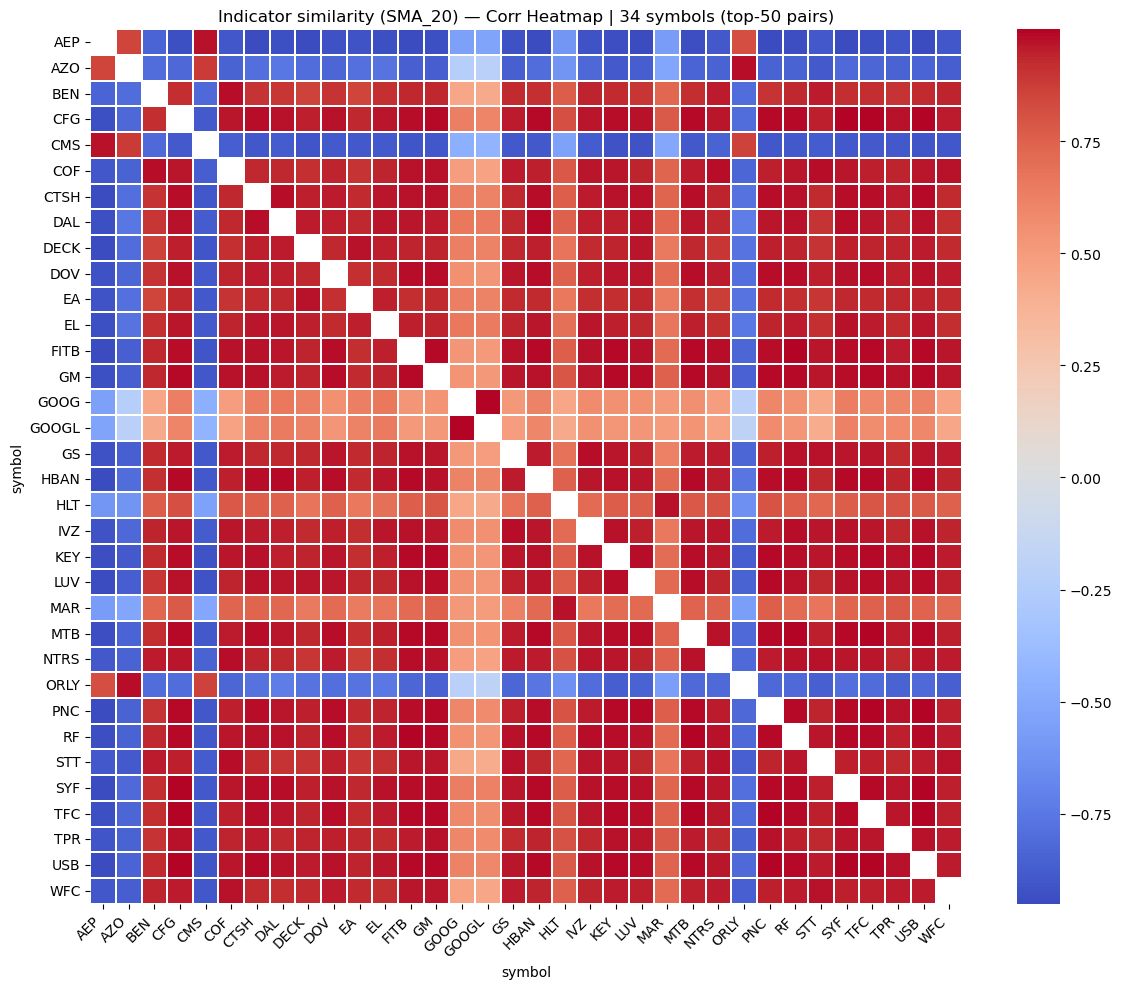

,symbol1,symbol2,sma_corr,sma_same_cluster
0,KEY,LUV,0.980297,True
1,HBAN,LUV,0.968890,True
2,LUV,RF,0.975442,True
3,AEP,CMS,0.972691,True
4,KEY,USB,0.987634,True
5,HLT,MAR,0.975028,True
6,CTSH,KEY,0.971907,True
7,GS,IVZ,0.978898,True
8,KEY,TFC,0.985075,True
9,KEY,MTB,0.983215,True


In [21]:
corr_sma = corr_cons["SMA_20"]
dist_sma = dist_cons["SMA_20"]

eda.plot_corr_heatmap(
    corr_sma,
    title="Indicator similarity (SMA_20) — Corr Heatmap | %d symbols (top-%d pairs)" % (meta_cons["n_symbols"], meta_cons["top_n"])
)

labels_sma = eda.agglom_labels_from_dist(dist_sma, n_clusters=n_clusters, linkage=linkage)

pairs_top = eda.pair_proximity_table(
    meta_cons["pairs_top"],
    corr_sma,
    labels_sma,
    top_n=top_n_pairs_table,
    corr_col_name="sma_corr",
    same_cluster_col="sma_same_cluster"
)

display(pairs_top)

### 3.3.4. Fazit
Hier kommt die Erklärung, warum die Cluster der Cointegration so sind und warum die Cluster der technischen Indikatoren so sind. Lässt sich das cross-validieren? --> Heatmap

Zum Schluss sollten die Daten der gewählten Paare in eine CSV-Datei geschreiben werden, damit es sauber gespeichert wird und im nächsten Dokument einfach eingelesen werden kann.

---

<div style="display: flex; justify-content: space-between; margin-top: 30px;">
  <a href="03_Preprocessing.ipynb">
    <button style="background-color:#007acc;color:white;border:none;padding:8px 12px;border-radius:6px;cursor:pointer;">
      Zurück
    </button>
  </a>
  <a href="05_Modellierung.ipynb">
    <button style="background-color:#007acc;color:white;border:none;padding:8px 12px;border-radius:6px;cursor:pointer;">
      Weiter
    </button>
  </a>
</div>
